<a href="https://colab.research.google.com/github/Gui-Domenico-UFMG/ia-generativa-ufmg-latent-flow/blob/main/notebooks/final_task_refactored.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Final Task - Latent Diffusion/Flow for the EMNIST dataset**

**Authors**: Guilherme Martins Dijan Domenico, João Paulo Lara Pinto, Fábio



## Overview

This notebook builds a **two-stage generative model** for handwritten characters (digits `0–9` and uppercase letters `A–Z`) from the EMNIST dataset.

The central idea is to **split the generation problem in two**:

| Stage | Model | What it learns | Why |
|---|---|---|---|
| 1 | **VAE / Conditional VAE** | A compressed, continuous 16‑D latent representation of each 28×28 image, plus a decoder that maps latents back to pixels | Working in 16 dimensions is far cheaper and smoother than working in 784 pixel dimensions |
| 2 | **Rectified Flow** (flow matching) | A velocity field that transports Gaussian noise $\mathcal{N}(0, I)$ to the *actual* distribution of latent codes | A VAE's latents never match $\mathcal{N}(0, I)$ exactly, so sampling directly from the prior produces off-manifold, blurry characters. The flow learns the true latent distribution |

**Generation pipeline (final model):**

$$
\underbrace{h \sim \mathcal{N}(0, I)}_{\text{noise, } t=1}
\;\xrightarrow{\;\text{ODE solver with } v_\theta(x,t)\;}\;
\underbrace{z}_{\text{latent, } t=0}
\;\xrightarrow{\;\text{CVAE decoder } \mu_D(z, y)\;}\;
\underbrace{\hat{x}}_{\text{28×28 image of class } y}
$$

**Bonus (Section 9):** a second, *class-conditional* flow $\Phi(z, t, c)$ on the unconditional VAE latents, sampled with **Classifier-Free Guidance**, so the class is chosen by the flow itself.

This is the same recipe used by large-scale latent diffusion models (e.g. Stable Diffusion), scaled down to a problem that trains in minutes on a single GPU.

### Table of contents

0. **Setup** — storage location and *train vs load* switches
1. **Data** — loading EMNIST, selecting 36 classes, fixing orientation
2. **Stage 1 models** — VAE and Conditional VAE (theory + architecture)
3. **Shared utilities** — plotting helpers and training loop
4. **Experiment 1** — unconditional VAE
5. **Experiment 2** — effect of the β parameter
6. **Experiment 3** — Conditional VAE (the autoencoder used in the final model)
7. **Stage 2: Latent Rectified Flow** — theory, architecture, training, diagnostics
8. **Full generation** — flow + conditional decoder
9. **Bonus: conditional flow + Classifier-Free Guidance** — $\Phi(z, t, c)$, guidance scale, classifier-based evaluation
10. **Interactive demo**
11. **Summary of findings**

> ⚙️ **Runtime:** use a GPU runtime (`Runtime → Change runtime type → GPU`). On a T4, the 30-epoch VAE takes ~7 min, the β sweep ~10 min, the 200-epoch CVAE ~45 min (timings from our run). The flow trains on 16‑D vectors and is much cheaper.
> Once the models are trained and saved, you can set the `TRAIN_*` flags in Section 0 to `False` to **load** them instead of retraining.

---
# 0. Setup and configuration

This cell controls **where results are stored**, **which models are trained or loaded**, and **what is written to disk**. Run it first.

**Storage.** Colab's local disk is erased when the runtime is recycled. Set `USE_GOOGLE_DRIVE = True` to save checkpoints, latents and figures to your Google Drive, so you can reload them in a later session.

**Train or load.** Each `TRAIN_*` flag chooses between training a model in this session (`True`) or loading a previously saved checkpoint (`False`). A newly trained model is always saved in its own folder. When loading, the checkpoint is looked up **first in `BASE_DIR`, then in the model's own folder** (`.safetensors` first, then the older `.pt` format):

| Flag | Own folder | Checkpoint (searched in `BASE_DIR`, then own folder) | Other files (own folder) |
|---|---|---|---|
| `TRAIN_VAE` | `VAE_DIR` | `vae.safetensors` | `latents.pt` (re-encoded if missing) |
| `TRAIN_CVAE` | `CVAE_DIR` | `cvae.safetensors` | `latents.pt` (re-encoded if missing; needed by the flow) |
| `TRAIN_FLOW` | `FLOW_DIR` | `flow_model.safetensors` | — |
| `TRAIN_CFG_FLOW` | `CFG_DIR` | `cfg_flow.safetensors` | — (uses the VAE and `VAE_DIR/latents.pt`) |

The flags are independent. For example, you can load the CVAE and train only a new flow on top of it. The EMNIST dataset is still downloaded in every case, because it is needed for the reconstruction plots and for encoding latents.

**β analysis.** `RUN_BETA_ANALYSIS = False` (default) skips Section 5: nothing is trained or loaded, and the figures from our run stay visible in its text cells. With `True`, `TRAIN_BETA_SWEEP` chooses between training the four models and loading them from `VAE_DIR/beta_<β>/` (searched only there, because all four use the same file name).

**Figures.** `SAVE_FIGURES = False` displays every figure without writing PNG files to disk.

> **Older checkpoints:** `.pt` files from previous versions of this notebook still load. The loss history of old VAE/CVAE checkpoints is read from `metrics.json`. An old `flow_model.pt` has no history, so its loss curves cannot be plotted.

In [1]:
import os
import json
import torch

# ---------------------------------------------------------------- storage
USE_GOOGLE_DRIVE = False   # True: keep checkpoints in Google Drive so they survive runtime resets

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/emnist_latent_flow"
else:
    BASE_DIR = "."

VAE_DIR = os.path.join(BASE_DIR, "outputs")   # unconditional VAE (+ β sweep in outputs/beta_<β>/)
CVAE_DIR = os.path.join(BASE_DIR, "cvae")     # conditional VAE + its latents (training data of the flow)
FLOW_DIR = os.path.join(BASE_DIR, "flow")     # rectified flow
CFG_DIR = os.path.join(BASE_DIR, "cfg_flow")  # bonus: class-conditional flow + CFG (Section 9)
for d in (VAE_DIR, CVAE_DIR, FLOW_DIR, CFG_DIR):
    os.makedirs(d, exist_ok=True)

# ---------------------------------------------------------------- train (True) or load (False)
# When loading, each checkpoint is looked up first in BASE_DIR, then in the model's own folder.
TRAIN_VAE = False
TRAIN_CVAE = False
TRAIN_FLOW = False
TRAIN_CFG_FLOW = False

# ---------------------------------------------------------------- β analysis (Section 5)
# False: skip Section 5 entirely (no training, no loading). The figures from our run stay
#        visible in the Section 5 text cells.
RUN_BETA_ANALYSIS = False
TRAIN_BETA_SWEEP = True    # only used if RUN_BETA_ANALYSIS = True (False: load from VAE_DIR/beta_<β>/)

# ---------------------------------------------------------------- figures
SAVE_FIGURES = False        # False: figures are only displayed, not written to disk

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | results folder: {os.path.abspath(BASE_DIR)}")

Device: cuda | results folder: /content


## 0.1 Checkpoint helpers

Model weights are saved in the **[safetensors](https://huggingface.co/docs/safetensors)** format (`*.safetensors`). Unlike `torch.save` (pickle), a safetensors file contains **only tensors**, so loading it cannot execute arbitrary code. It also loads faster. Non-tensor information (architecture config, best epoch, test metrics, loss history) is stored as JSON in the file's metadata header.

- **`save_model` / `load_model_file`** write and read a state dict plus its metadata. `load_model_file` also accepts the older `*.pt` checkpoints, so models trained with previous versions of this notebook still load.
- **`find_checkpoint(stem, model_dir)`** decides which file to load. It tries, in order: `BASE_DIR/<stem>.safetensors`, `BASE_DIR/<stem>.pt`, `model_dir/<stem>.safetensors`, `model_dir/<stem>.pt`. You can therefore either drop the checkpoints directly into `BASE_DIR` or keep them in their own folders.

Latent datasets (`latents.pt`) and metrics (`metrics.json`) are data, not model weights. They stay in each model's own folder and keep their current format.

In [2]:
try:
    from safetensors import safe_open
    from safetensors.torch import load_file, save_file
except ImportError:  # safetensors is preinstalled on Colab; install it elsewhere if needed
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "safetensors"])
    from safetensors import safe_open
    from safetensors.torch import load_file, save_file


def save_model(state_dict, path, meta=None):
    """Saves a state dict as .safetensors; `meta` (JSON-serializable dict) goes into the file header."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tensors = {k: v.detach().cpu().contiguous() for k, v in state_dict.items()}
    save_file(tensors, path, metadata={"meta": json.dumps(meta or {})})


def load_model_file(path, device="cpu"):
    """Returns (state_dict, meta) from a .safetensors file or from a legacy torch .pt checkpoint."""
    if path.endswith(".safetensors"):
        state_dict = load_file(path, device="cpu")
        with safe_open(path, framework="pt") as f:
            meta = json.loads((f.metadata() or {}).get("meta", "{}"))
    else:  # legacy checkpoint written with torch.save({"state_dict": ..., **meta})
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        state_dict = ckpt.pop("state_dict")
        meta = ckpt
    state_dict = {k: v.to(device) for k, v in state_dict.items()}
    return state_dict, meta


def find_checkpoint(stem, model_dir, search_base=True):
    """Path of the checkpoint to load: BASE_DIR first, then the model's own folder (.safetensors before .pt)."""
    dirs = ([BASE_DIR] if search_base else []) + [model_dir]
    candidates = [os.path.join(d, stem + ext) for d in dirs for ext in (".safetensors", ".pt")]
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        f"No checkpoint '{stem}' found. Looked for: {candidates}. "
        f"Train the model first (set its TRAIN_* flag to True) or copy the checkpoint into one of these folders."
    )

---
# 1. Data

## 1.1 Loading EMNIST and selecting 36 classes

We use the **EMNIST *balanced*** split, which has 47 classes and the same number of examples per class (so no class dominates training). Its labels are ordered as:

- `0–9` → digits
- `10–35` → uppercase letters `A–Z`
- `36–46` → a subset of lowercase letters (only those that look different from their uppercase form)

We **keep only labels `< 36`**, i.e. digits + uppercase letters. That gives **86,400 training** and **14,400 test** images (2,400 / 400 per class).

Some implementation details in the next cell:

- **`TransposeEMNIST`:** EMNIST images are stored transposed relative to MNIST. Without swapping height and width, every character would appear mirrored and rotated by 90°.
- **Pixel range `[0, 1]`:** `ToTensor()` scales pixels to `[0, 1]`. This matches the decoder's final `Sigmoid` and makes the squared-error reconstruction loss well scaled.
- **Mirror fallback:** the official NIST download server is often unavailable, so if `torchvision`'s download fails we download the same raw files from a public GitHub mirror.
- **`get_fake_datasets`:** synthetic "blob" images with the same shapes. They let you debug the whole pipeline without internet or a GPU (`fake=True`).
- **`drop_last=True`** on the training loader keeps every batch the same size, which keeps BatchNorm statistics stable.

In [3]:
import string
from typing import Tuple

import torch
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset

from torchvision import datasets, transforms

# Mapping of the 36 classes: 0..9 -> '0'..'9', 10..35 -> 'A'..'Z'
CLASS_NAMES = list(string.digits) + list(string.ascii_uppercase)
NUM_CLASSES = 36
IMG_SHAPE = (1, 28, 28)


def index_to_char(idx: int) -> str:
    """Class index (0..35) -> character ('0'-'9', 'A'-'Z')."""
    return CLASS_NAMES[idx] if 0 <= idx < NUM_CLASSES else "?"


def char_to_index(ch: str) -> int:
    """Character ('0'-'9' or 'A'-'Z', case-insensitive) -> index 0..35."""
    ch = ch.upper()
    if ch in CLASS_NAMES:
        return CLASS_NAMES.index(ch)
    raise ValueError(f"Invalid character '{ch}'. Use '0'-'9' or 'A'-'Z'.")


class TransposeEMNIST:
    """Fixes the orientation of EMNIST images (swaps height and width)."""

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        return tensor.transpose(-2, -1).contiguous()


# Public copy of the original NIST files (used only if the official download fails).
MIRROR_URL = "https://media.githubusercontent.com/media/aurelienduarte/emnist/master/gzip/"
MIRROR_FILES = [f"emnist-balanced-{s}-ubyte" for s in
                ("train-images-idx3", "train-labels-idx1", "test-images-idx3", "test-labels-idx1")]


def download_from_mirror(data_dir: str = "./data") -> None:
    """Downloads the 4 files of the 'balanced' split from the mirror into data_dir/EMNIST/raw (torchvision layout)."""
    import gzip
    import os
    import shutil
    import urllib.request

    raw = os.path.join(data_dir, "EMNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MIRROR_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        print(f"Downloading {name}.gz from the mirror...")
        urllib.request.urlretrieve(MIRROR_URL + name + ".gz", dst + ".gz")
        with gzip.open(dst + ".gz", "rb") as fin, open(dst, "wb") as fout:
            shutil.copyfileobj(fin, fout)
        os.remove(dst + ".gz")


def get_emnist_36_datasets(data_dir: str = "./data") -> Tuple[Dataset, Dataset]:
    """Returns (train, test) EMNIST datasets with 36 classes, images in [0, 1] and corrected orientation."""
    transform = transforms.Compose([transforms.ToTensor(), TransposeEMNIST()])

    def load(train: bool, download: bool):
        return datasets.EMNIST(root=data_dir, split="balanced", train=train, download=download, transform=transform)

    try:
        train_full, test_full = load(True, True), load(False, True)
    except Exception as e:  # NIST server down or blocked
        print(f"Official download failed ({type(e).__name__}); using the mirror.")
        download_from_mirror(data_dir)
        train_full, test_full = load(True, False), load(False, False)

    train_idx = torch.where(train_full.targets < NUM_CLASSES)[0].tolist()
    test_idx = torch.where(test_full.targets < NUM_CLASSES)[0].tolist()
    return Subset(train_full, train_idx), Subset(test_full, test_idx)


def get_fake_datasets(n_train: int = 2048, n_test: int = 512, seed: int = 0) -> Tuple[Dataset, Dataset]:
    """
    Fake data with the same format as EMNIST-36 (to test the code without downloading anything).
    Each class is a "blob" at a different position, so the VAE has something to learn.
    """
    g = torch.Generator().manual_seed(seed)

    def make(n: int) -> TensorDataset:
        y = torch.randint(0, NUM_CLASSES, (n,), generator=g)
        yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
        cy = 6 + (y // 6).float() * 3.2
        cx = 6 + (y % 6).float() * 3.2
        d2 = (yy[None] - cy[:, None, None]) ** 2 + (xx[None] - cx[:, None, None]) ** 2
        x = torch.exp(-d2 / 18.0) + 0.05 * torch.rand(n, 28, 28, generator=g)
        return TensorDataset(x.clamp(0, 1).unsqueeze(1), y)

    return make(n_train), make(n_test)


def get_dataloaders(
    data_dir: str = "./data",
    batch_size: int = 256,
    num_workers: int = 2,
    fake: bool = False,
) -> Tuple[DataLoader, DataLoader]:
    """Train (shuffled) and test DataLoaders. Use fake=True for a quick test without internet."""
    train_ds, test_ds = get_fake_datasets() if fake else get_emnist_36_datasets(data_dir)
    pin = torch.cuda.is_available()
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin, drop_last=True
    )
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin)
    return train_loader, test_loader

## 1.2 Sanity check: visualizing samples

Before training anything, we check that the images have the correct orientation and the labels match the characters.

In [4]:
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import torch

def _finish(fig, save_path: Optional[str], show: bool):
    fig.tight_layout()
    if save_path and SAVE_FIGURES:   # SAVE_FIGURES is set in Section 0
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        display(fig)
    plt.close(fig)


def plot_dataset_grid(images, labels, n: int = 36, save_path=None, show=True):
    """Grid of real dataset samples (checks orientation and labels)."""
    cols = 12
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.0, rows * 1.15))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            ax.imshow(images[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_title(index_to_char(int(labels[i])), fontsize=9)
    fig.suptitle("EMNIST-36 samples", fontsize=11)
    _finish(fig, save_path, show)

100%|██████████| 562M/562M [00:03<00:00, 171MB/s]


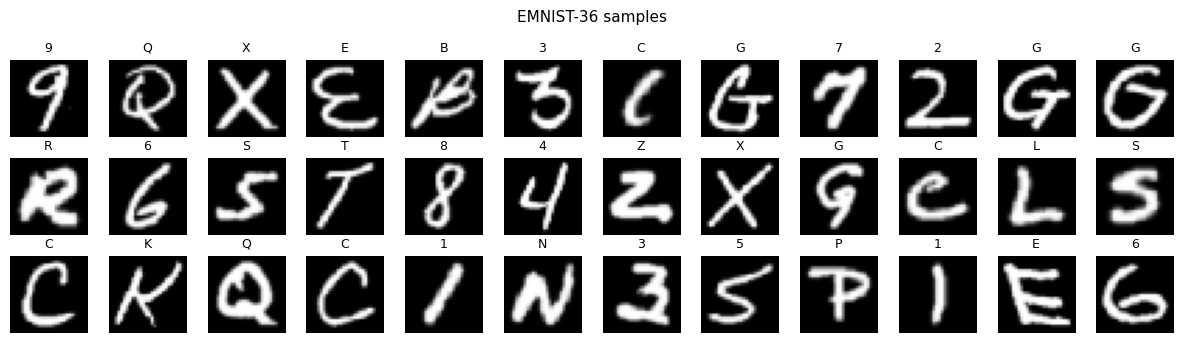

In [5]:
train_dl, test_dl = get_dataloaders()
x_vis, y_vis = next(iter(test_dl))
plot_dataset_grid(x_vis, y_vis, save_path=f"{BASE_DIR}/dataset_grid.png", show=True)

---
# 2. Stage 1 models: VAE and Conditional VAE

## 2.1 VAE theory

A Variational Autoencoder has two networks:

- **Encoder** $q(z \mid x) = \mathcal{N}\big(\mu_E(x),\ \operatorname{diag}\,\sigma_E^2(x)\big)$, which maps an image to a *distribution* over latent codes.
- **Decoder** $\mu_D(z)$, which maps a latent code back to an image.

**Reparameterization trick.** To backpropagate through sampling, we write the latent as a deterministic function of the encoder outputs plus independent noise:

$$Z(x) = \mu_E(x) + \sigma_E(x) \odot W, \qquad W \sim \mathcal{N}(0, I)$$

**Loss.** For each image, we minimize $\;R(x) + \beta\, L(x)$, where

- **Reconstruction error**, estimated by Monte Carlo with $K$ samples of $W$:
$$R(x) = \frac{1}{K}\sum_{k=1}^{K} \tfrac{1}{2}\,\big\lVert x - \mu_D(Z_k(x))\big\rVert^2$$
- **Latent error**, the closed-form KL divergence between the encoder distribution and the prior $\mathcal{N}(0, I)$:
$$L(x) = \mathrm{KL}\big(q(z\mid x)\,\|\,\mathcal{N}(0,I)\big) = \sum_{j=1}^{m}\Big[\tfrac{1}{2}(\sigma_j^2 - 1) - \log \sigma_j\Big] + \tfrac{1}{2}\lVert \mu_E(x) \rVert^2$$

**What β does.** $R$ pushes latents to carry as much information as possible about the image. $L$ pulls every $q(z\mid x)$ toward the same standard Gaussian. β sets the balance between them:

- **High β** gives a latent space that looks like $\mathcal{N}(0, I)$, so prior samples decode reasonably, but reconstructions are blurry.
- **Low β** gives sharp reconstructions, but the latents drift away from $\mathcal{N}(0, I)$, so decoding $z \sim \mathcal{N}(0, I)$ gives poor samples.

> 💡 **Interpretation of β as decoder noise.** The $\tfrac12\lVert x-\hat x\rVert^2$ term is the negative log-likelihood of a Gaussian decoder with variance $\sigma_D^2 = 1$. Minimizing $R + \beta L$ is equivalent to minimizing $R/\beta + L$, which is the exact ELBO for a decoder with $\sigma_D^2 = \beta$. With pixels in $[0,1]$, $\sigma_D = 1$ is a very weak likelihood, so a value of $\beta < 1$ is the natural choice, not an arbitrary hack. Our choice $\beta = 0.25$ corresponds to $\sigma_D = 0.5$.

**Why this matters for the two-stage design.** Stage 2 (the flow) learns whatever distribution the latents actually have. So we do **not** need a large β to force them toward $\mathcal{N}(0, I)$. We can choose a smaller β for better reconstructions and let the flow fix the prior mismatch.

## 2.2 VAE architecture

**Encoder** (image → $\mu_E, \log\sigma_E$):

| Layer | Output shape | Notes |
|---|---|---|
| Input | 1 × 28 × 28 | |
| Conv 3×3, stride 2 + BN + SiLU | 32 × 14 × 14 | Stride-2 convs downsample (learned pooling) |
| Conv 3×3, stride 2 + BN + SiLU | 64 × 7 × 7 | Channels double as resolution halves |
| Conv 3×3, stride 2 + BN + SiLU | 128 × 4 × 4 | |
| Flatten → Linear + SiLU | 256 | |
| Two linear heads | $m$ and $m$ (or 1) | $\mu_E$ and $\log\sigma_E$ |

**Decoder** (latent → image) is the mirror image:

| Layer | Output shape | Notes |
|---|---|---|
| Linear + SiLU → Linear + SiLU | 128·7·7 → reshape 128 × 7 × 7 | |
| ConvTranspose 4×4, stride 2 + BN + SiLU | 64 × 14 × 14 | Kernel 4 / stride 2 / padding 1 exactly doubles the size and avoids the checkerboard artifacts of odd kernels |
| ConvTranspose 4×4, stride 2 + BN + SiLU | 32 × 28 × 28 | |
| Conv 3×3 + **Sigmoid** | 1 × 28 × 28 | Sigmoid keeps output in $[0,1]$, the same range as the data |

**Design choices**

- **Latent dimension $m = 16$.** Large enough to encode the shape and style of 36 character classes; our experiments show **all 16 dimensions are active** (none collapse to the prior). Small enough that the Stage 2 flow can be a simple MLP.
- **Predicting $\log\sigma$ instead of $\sigma$.** This guarantees $\sigma > 0$ without constraints. It is **clamped to $[-10, 5]$** so `exp()` cannot overflow or underflow early in training.
- **`scalar_sigma` option.** Uses one shared σ per image (isotropic posterior) instead of one per dimension. We use the more expressive diagonal version (`scalar_sigma=False`).
- **SiLU activations** are smooth, so their gradients are well-behaved. **BatchNorm** in the conv stacks speeds up and stabilizes training.
- **~2.4M parameters.** This is modest and trains quickly on a single GPU.

The cell also defines `save_vae` / `load_vae` for checkpoints and `encode_dataset`, which maps a whole dataset to its latent means $\mu_E(x)$. Those latents become the training data for Stage 2.

In [6]:
from typing import Dict, Tuple

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

class Encoder(nn.Module):
    """(B, 1, 28, 28) -> mu_E (B, m), log sigma_E (B, m) ou (B, 1)."""

    def __init__(self, latent_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        # (1, 28, 28) -> (32, 14, 14) -> (64, 7, 7) -> (128, 4, 4)
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.SiLU(),
            nn.Flatten(),
        )
        self.fc = nn.Sequential(nn.Linear(128 * 4 * 4, 256), nn.SiLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_log_sigma = nn.Linear(256, 1 if scalar_sigma else latent_dim)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        h = self.fc(self.conv(x))
        mu = self.fc_mu(h)
        log_sigma = self.fc_log_sigma(h).clamp(-10.0, 5.0)  # numerical stability
        return mu, log_sigma


class Decoder(nn.Module):
    """(B, m) -> imagem (B, 1, 28, 28) em [0, 1]."""

    def __init__(self, latent_dim: int = 16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.SiLU(),
            nn.Linear(256, 128 * 7 * 7), nn.SiLU(),
        )
        # (128, 7, 7) -> (64, 14, 14) -> (32, 28, 28) -> (1, 28, 28)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.deconv(self.fc(z).view(-1, 128, 7, 7))


class VAE(nn.Module):
    def __init__(self, latent_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        self.latent_dim = latent_dim
        self.scalar_sigma = scalar_sigma
        self.encoder = Encoder(latent_dim, scalar_sigma)
        self.decoder = Decoder(latent_dim)

    @property
    def config(self) -> Dict:
        return {"latent_dim": self.latent_dim, "scalar_sigma": self.scalar_sigma}

    def encode(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Returns (mu_E(x), sigma_E(x)). sigma_E has shape (B, m) or (B, 1)."""
        mu, log_sigma = self.encoder(x)
        return mu, log_sigma.exp()

    @staticmethod
    def reparameterize(mu: torch.Tensor, sigma: torch.Tensor) -> torch.Tensor:
        """Z(x) = mu_E(x) + sigma_E(x) * W,  W ~ N(0, I)."""
        return mu + sigma * torch.randn_like(mu)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        """x_hat = mu_D(z)."""
        return self.decoder(z)

    def forward(self, x: torch.Tensor):
        mu, sigma = self.encode(x)
        z = self.reparameterize(mu, sigma)
        return self.decode(z), mu, sigma, z

    def compute_loss(self, x: torch.Tensor, beta: float = 1.0, num_mc_samples: int = 1) -> Dict[str, torch.Tensor]:
        """R(x) + beta * L(x), averaged over the batch (see Section 2.1)."""
        mu, log_sigma = self.encoder(x)
        sigma = log_sigma.exp()

        # R(x): Monte Carlo estimate with K = num_mc_samples samples of W
        recon = 0.0
        for _ in range(num_mc_samples):
            x_hat = self.decode(self.reparameterize(mu, sigma))
            recon = recon + 0.5 * ((x - x_hat) ** 2).sum(dim=(1, 2, 3))
        recon = (recon / num_mc_samples).mean()

        # L(x): closed form (KL between N(mu, sigma^2 I) and N(0, I))
        per_dim = 0.5 * (sigma ** 2 - 1.0) - log_sigma
        if self.scalar_sigma:
            sigma_term = self.latent_dim * per_dim.squeeze(-1)
        else:
            sigma_term = per_dim.sum(dim=1)
        latent = (sigma_term + 0.5 * (mu ** 2).sum(dim=1)).mean()

        return {"loss": recon + beta * latent, "recon_error": recon.detach(), "latent_error": latent.detach()}

# --------------------------------------------------------------------------------------
# Save / load
# --------------------------------------------------------------------------------------
def save_vae(vae: VAE, path: str, **extra) -> None:
    """Saves the weights as .safetensors; config and extra info (epoch, metrics, ...) go into the metadata."""
    save_model(vae.state_dict(), path, {"config": vae.config, **extra})


def load_vae(path: str, device="cpu", return_meta: bool = False):
    """Loads a VAE from a .safetensors (or legacy .pt) checkpoint."""
    state_dict, meta = load_model_file(path, device)
    vae = VAE(**meta["config"]).to(device)
    vae.load_state_dict(state_dict)
    vae.eval()
    return (vae, meta) if return_meta else vae

@torch.no_grad()
def encode_dataset(vae: VAE, loader: DataLoader, device) -> Dict[str, torch.Tensor]:
    """Encodes a whole dataset: returns {'mu': (N, m), 'sigma': (N, m|1), 'y': (N,)} on the CPU."""
    vae.eval()
    mus, sigmas, ys = [], [], []
    for x, y in loader:
        mu, sigma = vae.encode(x.to(device))
        mus.append(mu.cpu())
        sigmas.append(sigma.cpu())
        ys.append(y.cpu())
    return {"mu": torch.cat(mus), "sigma": torch.cat(sigmas), "y": torch.cat(ys)}

## 2.3 Conditional VAE (CVAE)

The CVAE has the same backbone, but **both networks also receive the class label $y$**:

- $q(z \mid x, y)$: the encoder concatenates the conv features (2048‑D) with a learned **class embedding** (`nn.Embedding(36, 16)`) before the FC layer.
- $\mu_D(z, y)$: the decoder concatenates $z$ with its own class embedding before the first linear layer.

**Why condition?** It gives us **control** over which character to generate. It also changes what the latent space represents. The decoder already knows the class from $y$, so the latent $z$ no longer needs to encode *which character* it is. It only needs to encode **style**: slant, stroke thickness, size, position. Section 6 shows this directly: the class centroids collapse to the origin of the latent space.

This has a practical consequence for Stage 2. Because $z$ is (approximately) **class-independent**, an **unconditional** flow over $z$ can be paired with a **conditional** decoder. We sample a style $z$ from the flow and choose the class $y$ freely.

**Embeddings instead of one-hot vectors.** A 16‑D learned embedding lets the network place similar characters (e.g. `O`/`0`, `I`/`1`) near each other. The decoder also accepts a **float embedding vector** directly in place of an integer label (see `ConditionalDecoder.forward`). The interpolation plot in Section 6 uses this to blend between two classes.

In [7]:
from typing import Dict, Tuple

import torch
import torch.nn as nn
from torch.utils.data import DataLoader


class ConditionalEncoder(nn.Module):
    """(B, 1, 28, 28), (B,) -> mu_E (B, m), log sigma_E (B, m) ou (B, 1)."""

    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()

        self.class_embed = nn.Embedding(num_classes, embed_dim)

        # (1, 28, 28) -> (32, 14, 14) -> (64, 7, 7) -> (128, 4, 4)
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.SiLU(),
            nn.Flatten(),
        )

        conv_output_dim = 128 * 4 * 4
        self.fc = nn.Sequential(nn.Linear(conv_output_dim + embed_dim, 256), nn.SiLU())

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_log_sigma = nn.Linear(256, 1 if scalar_sigma else latent_dim)

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        B = x.size(0)

        h_conv = self.conv(x)          # Shape: (B, 2048)

        h_class = self.class_embed(y)  # Shape: (B, embed_dim)
        h_combined = torch.cat([h_conv, h_class], dim=1) # Shape: (B, 2048 + embed_dim)

        h = self.fc(h_combined)
        mu = self.fc_mu(h)
        log_sigma = self.fc_log_sigma(h).clamp(-10.0, 5.0)

        return mu, log_sigma

class ConditionalDecoder(nn.Module):
    """(B, m), (B,) -> imagem (B, 1, 28, 28) em [0, 1]."""

    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16):
        super().__init__()

        self.class_embed = nn.Embedding(num_classes, embed_dim)

        self.fc = nn.Sequential(
            nn.Linear(latent_dim + embed_dim, 256), nn.SiLU(),
            nn.Linear(256, 128 * 7 * 7), nn.SiLU(),
        )

        # (128, 7, 7) -> (64, 14, 14) -> (32, 28, 28) -> (1, 28, 28)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.SiLU(),
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid(),
        )

    def forward(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # Extract class embedding
        if y.dtype in (torch.float16, torch.float32, torch.float64):
            h_class = y
        else:
            h_class = self.class_embed(y)

        # Concatenate latent vector z with the class embedding
        z_combined = torch.cat([z, h_class], dim=1) # Shape: (B, latent_dim + embed_dim)

        h = self.fc(z_combined)
        return self.deconv(h.view(-1, 128, 7, 7))


import torch
import torch.nn as nn
from typing import Dict, Tuple

class CVAE(nn.Module):
    def __init__(self, num_classes: int, latent_dim: int = 16, embed_dim: int = 16, scalar_sigma: bool = False):
        super().__init__()
        self.num_classes = num_classes
        self.latent_dim = latent_dim
        self.embed_dim = embed_dim
        self.scalar_sigma = scalar_sigma

        # Conditional Encoder and Decoder (using the conditional versions we built)
        self.encoder = ConditionalEncoder(num_classes, latent_dim, embed_dim, scalar_sigma)
        self.decoder = ConditionalDecoder(num_classes, latent_dim, embed_dim)

    @property
    def config(self) -> Dict:
        return {
            "num_classes": self.num_classes,
            "latent_dim": self.latent_dim,
            "embed_dim": self.embed_dim,
            "scalar_sigma": self.scalar_sigma
        }

    def encode(self, x: torch.Tensor, y: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """Returns (mu_E(x,y), sigma_E(x,y))."""
        mu, log_sigma = self.encoder(x, y)
        return mu, log_sigma.exp()

    @staticmethod
    def reparameterize(mu: torch.Tensor, sigma: torch.Tensor) -> torch.Tensor:
        """Z(x) = mu_E + sigma_E * W, W ~ N(0, I)."""
        return mu + sigma * torch.randn_like(mu)

    def decode(self, z: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        """x_hat = mu_D(z, y)."""
        return self.decoder(z, y)

    def forward(self, x: torch.Tensor, y: torch.Tensor):
        mu, sigma = self.encode(x, y)
        z = self.reparameterize(mu, sigma)
        return self.decode(z, y), mu, sigma, z

    def compute_loss(self, x: torch.Tensor, y: torch.Tensor, beta: float = 1.0, num_mc_samples: int = 1) -> Dict[str, torch.Tensor]:
        """R(x) + beta * L(x), averaged over the batch (see Section 2.1)."""
        mu, log_sigma = self.encoder(x, y)
        sigma = log_sigma.exp()

        # R(x): Monte Carlo estimate with K = num_mc_samples samples of W
        recon = 0.0
        for _ in range(num_mc_samples):
            x_hat = self.decode(self.reparameterize(mu, sigma), y)
            recon = recon + 0.5 * ((x - x_hat) ** 2).sum(dim=(1, 2, 3))
        recon = (recon / num_mc_samples).mean()

        # L(x): closed form (KL between N(mu, sigma^2 I) and N(0, I))
        per_dim = 0.5 * (sigma ** 2 - 1.0) - log_sigma
        if self.scalar_sigma:
            sigma_term = self.latent_dim * per_dim.squeeze(-1)
        else:
            sigma_term = per_dim.sum(dim=1)
        latent = (sigma_term + 0.5 * (mu ** 2).sum(dim=1)).mean()

        return {"loss": recon + beta * latent, "recon_error": recon.detach(), "latent_error": latent.detach()}

# --------------------------------------------------------------------------------------
# Save / load
# --------------------------------------------------------------------------------------
def save_cvae(cvae: CVAE, path: str, **extra) -> None:
    """Saves the weights as .safetensors; config and extra info (epoch, metrics, ...) go into the metadata."""
    save_model(cvae.state_dict(), path, {"config": cvae.config, **extra})


def load_cvae(path: str, device="cpu", return_meta: bool = False):
    """Loads a CVAE from a .safetensors (or legacy .pt) checkpoint."""
    state_dict, meta = load_model_file(path, device)
    cvae = CVAE(**meta["config"]).to(device)
    cvae.load_state_dict(state_dict)
    cvae.eval()
    return (cvae, meta) if return_meta else cvae


@torch.no_grad()
def encode_dataset_CVAE(cvae: CVAE, loader: DataLoader, device) -> Dict[str, torch.Tensor]:
    """Encodes a whole dataset: returns {'mu': (N, m), 'sigma': (N, m|1), 'y': (N,)} on the CPU."""
    cvae.eval()
    mus, sigmas, ys = [], [], []
    for x, y in loader:
        # Pass both x and y to the conditional encoder
        mu, sigma = cvae.encode(x.to(device), y.to(device))

        mus.append(mu.cpu())
        sigmas.append(sigma.cpu())
        ys.append(y.cpu())

    return {"mu": torch.cat(mus), "sigma": torch.cat(sigmas), "y": torch.cat(ys)}

---
# 3. Shared utilities

## 3.1 Plotting helpers

All visualization functions used in the experiments are defined here so the experiment sections stay short:

| Function | What it shows | Why it is useful |
|---|---|---|
| `plot_loss_curves` | Total, $R(x)$ and $L(x)$, train vs test | Detects over/underfitting and shows the R–L trade-off |
| `plot_reconstructions` | $x$ vs $\mu_D(\mu_E(x))$ | How much information the latent keeps |
| `plot_prior_samples(_cvae)` | $\mu_D(z)$ with $z \sim \mathcal{N}(0,I)$ | **Baseline generation without the flow** |
| `plot_*_by_beta`, `plot_beta_test_metrics` | Side-by-side comparison across β | Section 5 |
| `plot_interpolation(_cvae)` | Decoding points on a straight line between two latents | A smooth latent space gives gradual, plausible transitions |
| `plot_latent_pca` | 2D PCA of $\mu_E(x)$, colored by class | How classes are organized in latent space |

In [8]:
from typing import Dict, List, Optional

import numpy as np
import matplotlib.pyplot as plt
import torch

from IPython.display import display

EMNIST_CHARS = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
idx_to_char = {idx: char for idx, char in enumerate(EMNIST_CHARS)}
char_to_idx = {char: idx for idx, char in enumerate(EMNIST_CHARS)}

def _finish(fig, save_path: Optional[str], show: bool):
    fig.tight_layout()
    if save_path and SAVE_FIGURES:   # SAVE_FIGURES is set in Section 0
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        display(fig)
    plt.close(fig)

def plot_loss_curves(history: Dict[str, List[float]], save_path=None, show=True):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    fig.suptitle("Train and test loss curves", fontsize=14, y=1.05)
    for ax, key, title in zip(
        axes, ["loss", "recon_error", "latent_error"], ["Total loss", "Reconstruction R(x)", "Latent L(x)"]
    ):
        ax.plot(history[f"train_{key}"], label="Train")
        ax.plot(history[f"test_{key}"], label="Test")
        ax.set_title(title)
        ax.set_xlabel("epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    _finish(fig, save_path, show)


@torch.no_grad()
def plot_reconstructions(vae, images, labels=None, n: int = 12, conditional=False, save_path=None, show=True):
    """Topo: x original. Baixo: x_hat = mu_D(mu_E(x))."""
    vae.eval()
    device = next(vae.parameters()).device
    x = images[:n].to(device)
    if labels is not None:
        y = labels[:n].to(device)
    if conditional:
        mu, _ = vae.encode(x, y)
        x_hat = vae.decode(mu, y).cpu()
    else:
        mu, _ = vae.encode(x)
        x_hat = vae.decode(mu).cpu()
    fig, axes = plt.subplots(2, n, figsize=(n * 1.1, 2.6))
    fig.suptitle("Reconstructed samples", fontsize=14, y=1.05)
    for i in range(n):
        axes[0, i].imshow(x[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(x_hat[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[0, i].axis("off")
        axes[1, i].axis("off")
        if labels is not None:
            axes[0, i].set_title(index_to_char(int(labels[i])), fontsize=9)
    fig.suptitle("Original (top) vs. reconstruction μ_D(μ_E(x)) (bottom)", fontsize=11)
    _finish(fig, save_path, show)


@torch.no_grad()
def plot_prior_samples(vae: VAE, n: int = 64, seed: int = 0, save_path=None, show=True):
    """
    Decodes z ~ N(0, I) directly, WITHOUT the flow. Serves as a baseline:
    the flow should generate better characters than this.
    """
    vae.eval()
    device = next(vae.parameters()).device
    g = torch.Generator(device="cpu").manual_seed(seed)
    z = torch.randn(n, vae.latent_dim, generator=g).to(device)
    imgs = vae.decode(z).cpu()
    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle("VAE by itself: μ_D(z), z ~ N(0, I)  (baseline without Flow)", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_prior_samples_cvae(cvae: CVAE, n: int = 64, seed: int = 0, save_path=None, show=True):
    cvae.eval()
    device = next(cvae.parameters()).device
    g = torch.Generator(device="cpu").manual_seed(seed)

    labels_list = []
    for i in range(n):
        labels_list.append(i % cvae.num_classes)
    y = torch.tensor(labels_list, dtype=torch.long, device=device)
    z = torch.randn(n, cvae.latent_dim, generator=g).to(device)

    # 4. Decode using both z and the corresponding class labels y
    imgs = cvae.decode(z, y).cpu()

    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for i, (ax, img) in enumerate(zip(axes.flat, imgs)):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        # Optional: display the class name or index as a tiny title
        cls_idx = int(y[i].item())
        ax.set_title(idx_to_char[cls_idx], fontsize=6, pad=1)

    fig.suptitle("CVAE Baseline: μ_D(z, y), z ~ N(0, I) (no Flow)", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_prior_samples_by_beta(models_info, seed=0, save_path=None, show=True):
    rows = 7
    cols = len(models_info)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5), squeeze=False)
    g = torch.Generator(device="cpu").manual_seed(seed)

    latent_dim = models_info[0]["model"].latent_dim
    device = next(models_info[0]["model"].parameters()).device

    z = torch.randn(rows, latent_dim, generator=g).to(device)

    for col_idx, info in enumerate(models_info):
        beta = info["beta"]
        vae = info["model"]

        vae.eval()
        model_device = next(vae.parameters()).device
        imgs = vae.decode(z.to(model_device)).cpu()

        for row_idx in range(rows):
            ax = axes[row_idx, col_idx]
            img = imgs[row_idx]

            if img.ndim == 3:
                img = img[0]

            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row_idx == 0:
                ax.set_title(f"β = {beta}", fontsize=11, fontweight="bold")

    fig.suptitle("Prior VAE (z ~ N(0, I)) per Beta value", fontsize=12, y=1.02)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_reconstructions_by_beta(models_info, test_images, save_path=None, show=True):
    rows = 7
    test_images = test_images[:rows]

    cols = len(models_info)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.5, rows * 1.5), squeeze=False)

    for col_idx, info in enumerate(models_info):
        beta = info["beta"]
        vae = info["model"]

        vae.eval()
        device = next(vae.parameters()).device
        x = test_images.to(device)

        out = vae(x)
        recon_imgs = out[0] if isinstance(out, (tuple, list)) else out
        recon_imgs = recon_imgs.cpu()

        for row_idx in range(rows):
            ax = axes[row_idx, col_idx]
            img = recon_imgs[row_idx]

            if img.ndim == 3:
                img = img[0]

            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row_idx == 0:
                ax.set_title(f"β = {beta}", fontsize=11, fontweight="bold")

    fig.suptitle("VAE reconstruction comparison per Beta", fontsize=12, y=1.02)
    _finish(fig, save_path, show)

def plot_beta_test_metrics(results_list, save_path=None, show=True):
    if not results_list:
        print("The result list is empty.")
        return

    betas = [item["beta"] for item in results_list]

    first_test_metrics = results_list[0]["metrics"]["best_test"]
    metric_names = [m for m, val in first_test_metrics.items() if isinstance(val, (int, float))]

    n_betas = len(betas)
    n_metrics = len(metric_names)

    fig, ax = plt.subplots(figsize=(8, 4))

    x = np.arange(n_metrics)
    width = 0.8 / n_betas

    for i, item in enumerate(results_list):
        beta = item["beta"]
        test_metrics = item["metrics"]["best_test"]

        values = [test_metrics.get(m, 0) for m in metric_names]

        offset = (i - n_betas / 2 + 0.5) * width
        ax.bar(x + offset, values, width, label=f"β = {beta}")

    ax.set_xlabel("Metric", fontsize=11, fontweight="bold")
    ax.set_ylabel("Loss value", fontsize=11, fontweight="bold")
    ax.set_title("Test loss comparison by Beta", fontsize=13, fontweight="bold", pad=12)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_names, rotation=15, ha="right")
    ax.legend(title="Beta values", frameon=True)
    ax.grid(axis="y", alpha=0.3)

    _finish(fig, save_path, show)

@torch.no_grad()
def plot_interpolation(vae: VAE, x_a, x_b, y_a, y_b, steps: int = 10, save_path=None, show=True):
    """Linear interpolation in latent space between two images: shows whether the latent space is 'smooth'."""
    vae.eval()
    device = next(vae.parameters()).device
    mu_a, _ = vae.encode(x_a[None].to(device))
    mu_b, _ = vae.encode(x_b[None].to(device))
    t = torch.linspace(0, 1, steps, device=device)[:, None]
    imgs = vae.decode((1 - t) * mu_a + t * mu_b).cpu()
    fig, axes = plt.subplots(1, steps, figsize=(steps * 1.1, 1.4))
    for ax, img in zip(axes, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle("Linear Interpolation in the Latent Space", fontsize=10)
    _finish(fig, save_path, show)

@torch.no_grad()
def plot_interpolation_cvae(cvae: CVAE, x_a, x_b, y_a, y_b, steps: int = 10, save_path=None, show=True):
    """Linear interpolation in latent space between two images, with class conditioning."""
    cvae.eval()
    device = next(cvae.parameters()).device

    # 1. Encode both images with their respective class labels
    mu_a, _ = cvae.encode(x_a[None].to(device), torch.tensor([y_a], device=device))
    mu_b, _ = cvae.encode(x_b[None].to(device), torch.tensor([y_b], device=device))

    # 2. Linear interpolation in latent space
    t = torch.linspace(0, 1, steps, device=device)[:, None]
    z = (1.0 - t) * mu_a + t * mu_b  # Shape: (steps, latent_dim)

    ya_t = torch.tensor([y_a], dtype=torch.long, device=device)
    yb_t = torch.tensor([y_b], dtype=torch.long, device=device)

    emb_a = cvae.decoder.class_embed(ya_t)
    emb_b = cvae.decoder.class_embed(yb_t)
    y_emb_steps = (1.0 - t) * emb_a + t * emb_b

    imgs = cvae.decode(z, y_emb_steps).cpu()

    fig, axes = plt.subplots(1, steps, figsize=(steps * 1.1, 1.4))
    for ax, img in zip(axes, imgs):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

    fig.suptitle("Linear interpolation in the latent space (CVAE)", fontsize=10)
    _finish(fig, save_path, show)

def plot_latent_pca(mu: torch.Tensor, y: torch.Tensor, max_points: int = 8000, save_path=None, show=True):
    """2D PCA projection of mu_E(x), colored by class, with each character drawn at its class centroid."""
    idx = torch.randperm(len(mu))[:max_points]
    m, yy = mu[idx], y[idx]
    m = m - m.mean(0)
    _, _, v = torch.pca_lowrank(m, q=2, center=False)
    p = m @ v[:, :2]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(p[:, 0], p[:, 1], c=yy, cmap="nipy_spectral", s=2, alpha=0.5, vmin=0, vmax=NUM_CLASSES - 1)
    for c in range(NUM_CLASSES):
        sel = yy == c
        if sel.any():
            cx, cy = p[sel].mean(0)
            ax.text(float(cx), float(cy), CLASS_NAMES[c], fontsize=10, weight="bold", ha="center", va="center")
    ax.set_title("Latent Space μ_E(x) — PCA 2D")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    _finish(fig, save_path, show)

## 3.2 Training loop and latent export

**`train_vae`** trains either a VAE or a CVAE (`conditional=True`). It:

1. Runs one epoch of minibatch optimization on $R + \beta L$.
2. Evaluates on the test set (`evaluate`).
3. Saves a checkpoint whenever the test loss improves, and **reloads the best checkpoint** at the end.

> ⚠️ Strictly speaking, we use the test split for model selection, so the reported "test" numbers are slightly optimistic. A held-out validation split would be cleaner. In practice the train/test curves are close, so the effect is small.

**`encode_and_export_latents`** encodes the full train and test sets and saves `latents.pt`, which is the **dataset for Stage 2**. It also saves:

- **`active_dims`:** the number of latent dimensions whose $\mu_E(x)$ varies across images (variance > 0.01). A dimension with near-zero variance has *collapsed* to the prior and carries no information.
- **`mu_mean` / `mu_std`:** latent statistics, available for normalizing the flow's input. They turned out not to be necessary (see Section 7).

**Loading instead of training.** When a `TRAIN_*` flag is `False`, two helpers are used instead:

- **`load_trained_autoencoder`** rebuilds the VAE/CVAE from its checkpoint (the architecture is stored inside it) and reads the training history stored in the checkpoint (or, for older checkpoints, from `metrics.json`), so the loss curves can still be plotted. It returns the same `(model, history, ckpt)` as `train_vae`, so the rest of the notebook works the same either way. The checkpoint file is chosen by `find_checkpoint` (Section 0.1).
- **`load_or_export_latents`** reuses `latents.pt` if it exists instead of re-encoding the dataset.

In [9]:
import argparse
import json
import os
import time

import matplotlib

matplotlib.use("Agg")
import torch  # noqa: E402
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

@torch.no_grad()
def evaluate(model, loader, device, beta: float, conditional: bool):
    model.eval()
    tot = {"loss": 0.0, "recon_error": 0.0, "latent_error": 0.0}
    n = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        if conditional:
            out = model.compute_loss(x, y, beta=beta)
        else:
            out = model.compute_loss(x, beta=beta)
        for k in tot:
            tot[k] += float(out[k]) * len(x)
        n += len(x)
    return {k: v / n for k, v in tot.items()}


def train_vae(
    model,
    train_loader,
    test_loader,
    optim,
    sched,
    latent_dim=16,
    scalar_sigma=False,
    beta=0.25,
    epochs=30,
    batch_size=256,
    lr=1e-3,
    num_workers=2,
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    seed=42,
    data_dir="./data",
    out_dir="./outputs",
    conditional=False,
    fake=False
):
    print(f"Training latent_dim={latent_dim}, epochs={epochs}, lr={lr}")

    torch.manual_seed(seed)
    os.makedirs(out_dir, exist_ok=True)
    out = lambda name: os.path.join(out_dir, name)  # noqa: E731
    print(f"Device: {device}")

    # 1) Data
    print(f"Train: {len(train_loader.dataset)} images | Test: {len(test_loader.dataset)} images")

    # 2) Model
    n_params = sum(p.numel() for p in model.parameters())
    print(f"VAE: m={latent_dim}, sigma {'scalar' if scalar_sigma else 'diagonal'}, "
          f"beta={beta}, {n_params/1e6:.2f}M parameters")

    # 3) Training
    history = {f"{s}_{k}": [] for s in ("train", "test") for k in ("loss", "recon_error", "latent_error")}
    best_test = float("inf")
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        tot = {"loss": 0.0, "recon_error": 0.0, "latent_error": 0.0}
        n = 0
        for x, y in train_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            if conditional:
                losses = model.compute_loss(x, y, beta=beta)
            else:
                losses = model.compute_loss(x, beta=beta)
            optim.zero_grad(set_to_none=True)
            losses["loss"].backward()
            optim.step()
            for k in tot:
                tot[k] += losses[k].item() * len(x)
            n += len(x)
        sched.step()
        train_m = {k: v / n for k, v in tot.items()}
        test_m = evaluate(model, test_loader, device, beta, conditional)
        for k in tot:
            history[f"train_{k}"].append(train_m[k])
            history[f"test_{k}"].append(test_m[k])
        print(f"[{epoch:02d}/{epochs}] train: loss {train_m['loss']:.2f} "
              f"(R {train_m['recon_error']:.2f}, L {train_m['latent_error']:.2f}) | "
              f"test: loss {test_m['loss']:.2f} (R {test_m['recon_error']:.2f}, L {test_m['latent_error']:.2f}) "
              f"| {time.time() - t0:.0f}s")
        if test_m["loss"] < best_test:
            best_test = test_m["loss"]
            if conditional:
                save_cvae(model, out("cvae.safetensors"), epoch=epoch, test_metrics=test_m, beta=beta)
            else:
                save_vae(model, out("vae.safetensors"), epoch=epoch, test_metrics=test_m, beta=beta)

    # Reload the best checkpoint (lowest test loss) and store the full loss history in it
    ckpt_path = out("cvae.safetensors" if conditional else "vae.safetensors")
    state_dict, ckpt = load_model_file(ckpt_path, device)
    model.load_state_dict(state_dict)
    ckpt["history"] = history
    save_fn = save_cvae if conditional else save_vae
    save_fn(model, ckpt_path, **{k: v for k, v in ckpt.items() if k != "config"})
    print(f"Best epoch: {ckpt['epoch']} (test loss: {best_test:.2f}) -> {ckpt_path}")


    return model, history, ckpt

def encode_and_export_latents(vae, train_loader, test_loader, ckpt, latent_dim, history, device, out_dir, metrics_only = False, conditional = False):
    os.makedirs(out_dir, exist_ok=True)
    out = lambda name: os.path.join(out_dir, name)
    plain_train = torch.utils.data.DataLoader(train_loader.dataset, batch_size=512, shuffle=False)
    if conditional:
        lat_train = encode_dataset_CVAE(vae, plain_train, device)
        lat_test = encode_dataset_CVAE(vae, test_loader, device)
    else:
        lat_train = encode_dataset(vae, plain_train, device)
        lat_test = encode_dataset(vae, test_loader, device)
    mu = lat_train["mu"]
    # "active" dimensions: variance of mu_E(x) across images > 0.01 (the VAE does not use the others)
    active_dims = int((mu.var(0) > 0.01).sum())
    if not metrics_only:
        latents = {
                "train": lat_train,
                "test": lat_test,
                "latent_dim": latent_dim,
                "class_names": CLASS_NAMES,
                "mu_mean": mu.mean(0),  # statistics for normalizing the latent in the flow
                "mu_std": mu.std(0),
            }
        torch.save(latents, out("latents.pt"),)

        print(f"Latents saved in {out('latents.pt')}: train {tuple(mu.shape)}, test {tuple(lat_test['mu'].shape)}")
        print(f"Statistics of mu_E(x): mean {mu.mean():.3f}, standard deviation {mu.std():.3f}, "
              f"active dimensions {active_dims}/{latent_dim}")

    n_params = sum(p.numel() for p in vae.parameters())
    metrics = {"best_epoch": ckpt["epoch"], "best_test": ckpt["test_metrics"],
                    "active_dims": active_dims, "n_params": n_params, "history": history}
    with open(out("metrics.json"), "w") as f:
          json.dump(metrics, f, indent=2)
    print("Metrics saved")
    if not metrics_only:
        return latents
    else:
        return metrics


# --------------------------------------------------------------------------------------
# Loading previously trained models (used when a TRAIN_* flag is False)
# --------------------------------------------------------------------------------------
def load_trained_autoencoder(out_dir, device, conditional=False, search_base=True):
    """
    Loads a VAE/CVAE checkpoint saved by train_vae() (BASE_DIR first, then out_dir; see find_checkpoint)
    and its training history. Returns the same (model, history, ckpt) triple as train_vae().
    """
    path = find_checkpoint("cvae" if conditional else "vae", out_dir, search_base=search_base)
    loader = load_cvae if conditional else load_vae
    model, ckpt = loader(path, device, return_meta=True)

    # The history is stored in the checkpoint; older checkpoints only have it in metrics.json
    history = ckpt.get("history")
    metrics_path = os.path.join(out_dir, "metrics.json")
    if history is None and os.path.exists(metrics_path):
        with open(metrics_path) as f:
            history = json.load(f).get("history")

    print(f"Loaded {path} (best epoch {ckpt['epoch']}, test loss {ckpt['test_metrics']['loss']:.2f})")
    return model, history, ckpt


def load_or_export_latents(model, train_loader, test_loader, ckpt, latent_dim, history, device,
                           out_dir, conditional=False, recompute=True):
    """
    Returns the latent dataset of a trained (C)VAE. If recompute=False and out_dir/latents.pt
    already exists, it is loaded from disk; otherwise the dataset is encoded and exported again.
    """
    path = os.path.join(out_dir, "latents.pt")
    if recompute or not os.path.exists(path):
        return encode_and_export_latents(model, train_loader, test_loader, ckpt, latent_dim, history,
                                         device, out_dir, conditional=conditional)
    latents = torch.load(path, map_location="cpu")
    print(f"Loaded latents from {path}: train {tuple(latents['train']['mu'].shape)}, "
          f"test {tuple(latents['test']['mu'].shape)}")
    return latents

---
# 4. Experiment 1: Unconditional VAE

## 4.1 Hyperparameters and training

> With `TRAIN_VAE = False`, the cell below loads `vae.safetensors` (or a legacy `vae.pt`) instead of training, looking first in `BASE_DIR` and then in `VAE_DIR`.

| Hyperparameter | Value | Rationale |
|---|---|---|
| `latent_dim` | 16 | See Section 2.2 |
| `scalar_sigma` | `False` | A diagonal posterior is more expressive |
| `beta` | 0.25 | Balances sharp reconstructions with a reasonably regular latent space ($\sigma_D = 0.5$, see Section 2.1). Section 5 compares other values |
| `epochs` | 200 | The loss curves flatten by then |
| `batch_size` | 256 | Large enough for stable BatchNorm statistics and good GPU utilization |
| Optimizer | AdamW, `lr=1e-3`, `weight_decay=1e-4` | Standard, robust defaults for convnets. Decoupled weight decay provides light regularization |
| Scheduler | Cosine annealing over all epochs | Large steps early for fast progress, small steps at the end to settle into a minimum without manual LR tuning |

In [10]:
# PARAMETERS
latent_dim = 16
scalar_sigma = False
beta = 0.25
epochs = 200
batch_size = 256
lr = 1e-3
num_workers = 2

train_dl, test_dl = get_dataloaders(batch_size=batch_size, num_workers=num_workers)

if TRAIN_VAE:
    model = VAE(latent_dim, scalar_sigma).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    trained_model, history, ckpt = train_vae(model, train_dl, test_dl, opt, sched, latent_dim, scalar_sigma,
                                             beta, epochs, batch_size, lr, num_workers, device, out_dir=VAE_DIR)
else:
    trained_model, history, ckpt = load_trained_autoencoder(VAE_DIR, device, conditional=False)

Loaded ./vae.safetensors (best epoch 193, test loss 10.67)


Next, we encode the dataset with the trained VAE and save the latents. The number of active dimensions is printed.

In [11]:
# Export (or reload) the latent vectors of the dataset
latents = load_or_export_latents(trained_model, train_dl, test_dl, ckpt, latent_dim, history, device,
                                 VAE_DIR, conditional=False, recompute=TRAIN_VAE)

Latents saved in ./outputs/latents.pt: train (86400, 16), test (14400, 16)
Statistics of mu_E(x): mean 0.001, standard deviation 0.937, active dimensions 16/16
Metrics saved


## 4.2 Results

**Loss curves.** $R(x)$ decreases steadily while $L(x)$ *increases* in the first epochs and then plateaus. This is the expected trade-off: the encoder learns to put more information into $z$, which moves $q(z\mid x)$ away from the prior. Train and test curves stay close, so there is no significant overfitting.

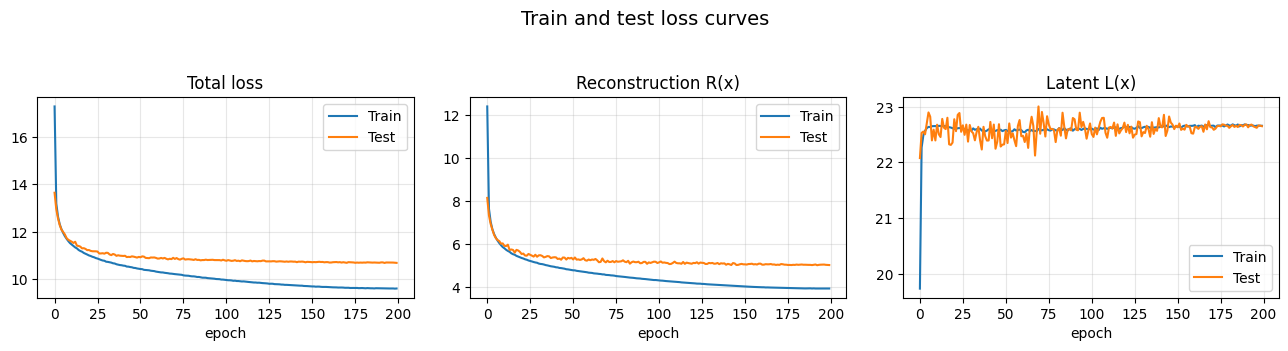

In [12]:
# Loss curves visualization (needs the training history: from this session or from metrics.json)
if history:
    plot_loss_curves(history, save_path=f"{VAE_DIR}/vae_loss_curves.png", show=True)
else:
    print("No training history available for this checkpoint.")

**Reconstructions.** Top: original test images. Bottom: $\mu_D(\mu_E(x))$, decoded from the posterior mean (no sampling noise). The overall shape is preserved and fine details are slightly smoothed, as is typical for a VAE with a Gaussian likelihood.

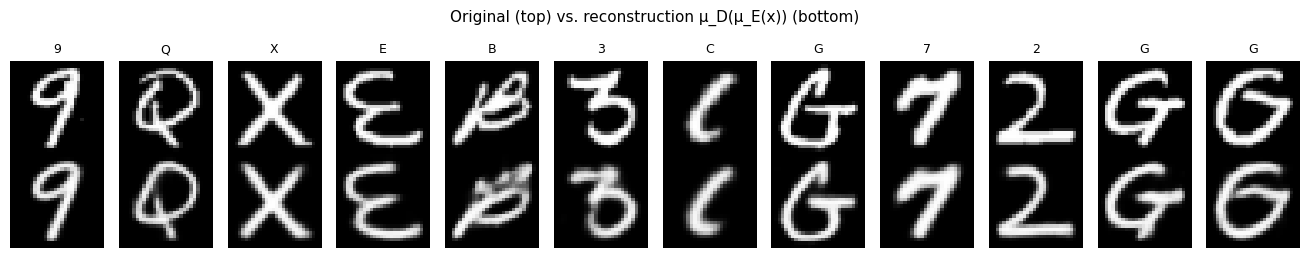

In [13]:
# Reconstruction visualization
x_vis, y_vis = next(iter(test_dl))
plot_reconstructions(trained_model, x_vis, y_vis, save_path=f"{VAE_DIR}/vae_reconstructions.png", show=True)

**Prior samples (baseline without the flow).** We decode $z \sim \mathcal{N}(0, I)$ directly. Many samples are **not valid characters**: they are hybrids or ambiguous strokes. This is the **prior hole problem**. The *aggregate posterior* $q(z) = \mathbb{E}_x[q(z\mid x)]$ does not fill $\mathcal{N}(0, I)$ uniformly, so many prior samples land in regions the decoder never saw during training. **This is the motivation for Stage 2.**

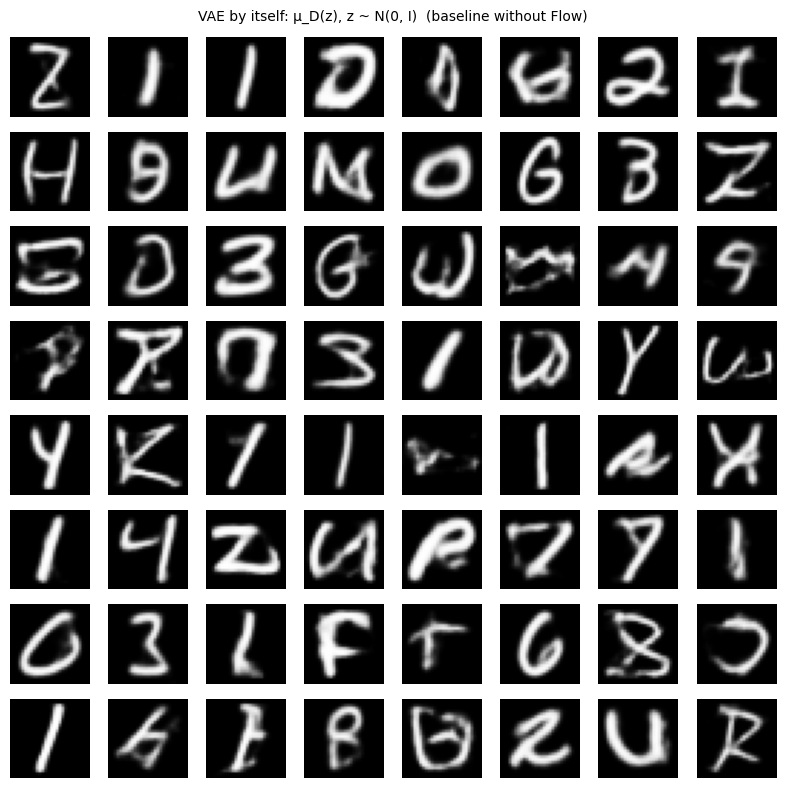

In [14]:
# Visualize VAE generation (no flow)
plot_prior_samples(trained_model, save_path=f"{VAE_DIR}/vae_prior_samples.png", show=True)

**Latent interpolation.** We decode points on the line $(1-t)\,\mu_E(x_a) + t\,\mu_E(x_b)$. The transition is gradual, which shows the latent space is smooth. The intermediate images, however, are not always valid characters.

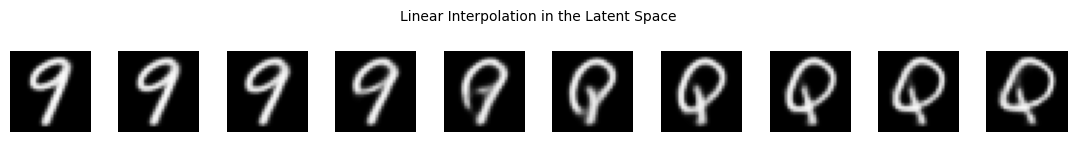

In [15]:
# Visualize linear interpolation in the latent space
plot_interpolation(trained_model, x_vis[0], x_vis[1], y_vis[0].item(), y_vis[1].item(), save_path=f"{VAE_DIR}/vae_interpolation.png", show=True)

**Latent space (PCA).** Class centroids (bold labels) are spread across the space. The unconditional VAE **must encode class identity in $z$**, because it has no other way to know which character to draw. Compare this with the CVAE in Section 6.

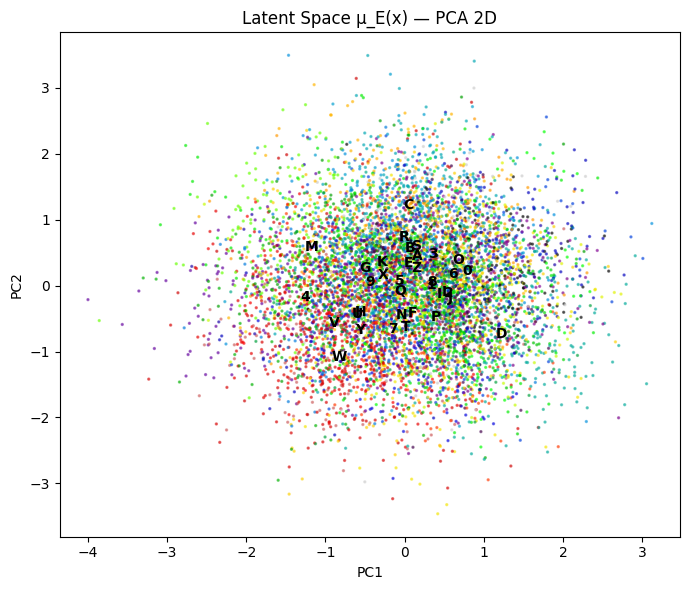

In [16]:
# Visualize two principal components of the samples in latent space
plot_latent_pca(latents["test"]["mu"], latents["test"]["y"], save_path=f"{VAE_DIR}/vae_latent_pca.png", show=True)

---
# 5. Experiment 2: Effect of β

To support the choice of β, we train four VAEs with $\beta \in \{1.0,\ 0.5,\ 0.25,\ 0.05\}$, keeping everything else fixed. We use 10 epochs each to keep the sweep cheap; this is enough to see the trend.

Final test values after 10 epochs:

| β | $R(x)$ (recon.) | $L(x)$ (KL) |
|---|---|---|
| 1.0 | 12.72 | 9.75 |
| 0.5 | 8.20 | 16.03 |
| 0.25 | 5.68 | 22.92 |
| 0.05 | 3.52 | 39.45 |

As β decreases, reconstruction error drops by ~3.6× while the KL term grows by ~4×. The latents carry more information but are further from $\mathcal{N}(0,I)$.

> **This section is skipped by default** (`RUN_BETA_ANALYSIS = False` in Section 0): nothing is trained or loaded, and the figures from our run are embedded in the text cells below. To reproduce it, set `RUN_BETA_ANALYSIS = True`. Then `TRAIN_BETA_SWEEP` chooses between training the four models (~10 min on GPU) and loading them from `VAE_DIR/beta_<β>/`.

In [17]:
# PARAMETERS (same as Experiment 1, but only 10 epochs per β)
latent_dim = 16
scalar_sigma = False
epochs = 10
batch_size = 256
lr = 1e-3
num_workers = 2
BETAS = [1.0, 0.5, 0.25, 0.05]

if not RUN_BETA_ANALYSIS:
    print("β analysis skipped (RUN_BETA_ANALYSIS = False in Section 0). The figures from our run are shown in the text cells.")
else:
    beta_train_dl, beta_test_dl = get_dataloaders(batch_size=batch_size, num_workers=num_workers)
    models = []
    metrics_list = []

    for b in BETAS:
        out_dir = os.path.join(VAE_DIR, f"beta_{b}")
        if TRAIN_BETA_SWEEP:
            model = VAE(latent_dim, scalar_sigma).to(device)
            opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
            b_model, b_history, b_ckpt = train_vae(model, beta_train_dl, beta_test_dl, opt, sched, latent_dim, scalar_sigma,
                                                   b, epochs, batch_size, lr, num_workers, device, out_dir=out_dir)
            metrics = encode_and_export_latents(b_model, beta_train_dl, beta_test_dl, b_ckpt, latent_dim, b_history, device,
                                                out_dir=out_dir, metrics_only=True)
        else:
            # every β has a checkpoint with the same name, so only its own folder is searched (not BASE_DIR)
            b_model, _, _ = load_trained_autoencoder(out_dir, device, conditional=False, search_base=False)
            with open(os.path.join(out_dir, "metrics.json")) as f:
                metrics = json.load(f)
        metrics_list.append({"beta": b, "metrics": metrics})
        models.append({"beta": b, "model": b_model})

β analysis skipped (RUN_BETA_ANALYSIS = False in Section 0). The figures from our run are shown in the text cells.


**Reconstructions per β.** Each row is the same test image. With β = 1.0, reconstructions are blurry and sometimes change the character (row 4: an `E` becomes closer to a `B`). With β ≤ 0.25 they are sharp and faithful.

*Figure from our run (10 epochs per β):*

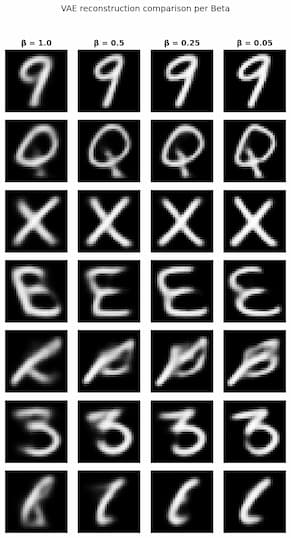

In [18]:
if RUN_BETA_ANALYSIS:
    x_vis, y_vis = next(iter(beta_test_dl))
    plot_reconstructions_by_beta(models, x_vis, save_path=f"{VAE_DIR}/reconstructions_by_beta.png", show=True)

**Prior samples per β** (the same $z$ in each row). There is no clear winner. High β gives blurry but "average" shapes. Low β gives sharper strokes but more malformed characters, because more prior samples fall outside the region the encoder actually uses.

*Figure from our run (10 epochs per β):*

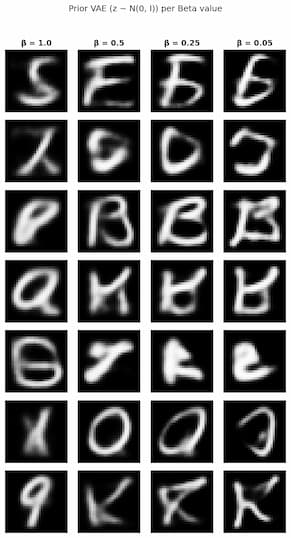

In [19]:
if RUN_BETA_ANALYSIS:
    plot_prior_samples_by_beta(models, seed=42, save_path=f"{VAE_DIR}/beta_generation_comparison.png", show=True)

**Test metrics per β.**

> ⚠️ The **total loss** bars are *not* comparable across β, because each model minimizes a different objective ($R + \beta L$ with a different β). Only the separate $R$ and $L$ bars are meaningful to compare.

*Figure from our run (10 epochs per β):*

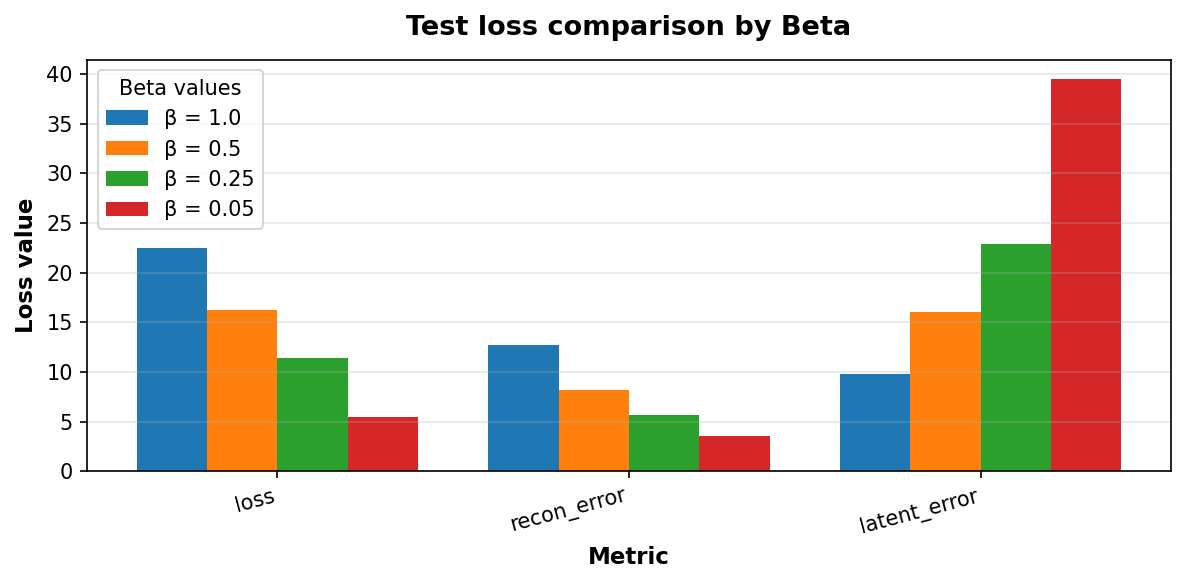

In [20]:
if RUN_BETA_ANALYSIS:
    plot_beta_test_metrics(metrics_list, save_path=f"{VAE_DIR}/betas_metrics_comparison.png")

**Conclusion and choice of β = 0.25.** β = 0.05 reconstructs best, but its KL is ~1.7× higher, so the latent distribution is more irregular and harder for the flow to model. β = 1.0 has a smooth latent space but blurry decoding, and the flow cannot fix a blurry decoder. **β = 0.25 is a good compromise**: reconstructions are almost as sharp as β = 0.05, and the latent space is still compact and well-behaved (the final CVAE trained with β = 0.25 has latents with mean ≈ 0 and std ≈ 0.87). This is what the flow needs.

---
# 6. Experiment 3: Conditional VAE

This is the autoencoder used in the final model. It uses the same hyperparameters as Section 4 (β = 0.25, $m$ = 16, AdamW 1e‑3, cosine schedule), plus:

| Hyperparameter | Value | Rationale |
|---|---|---|
| `embed_dim` | 16 | Same size as the latent, so the class signal is not drowned out by the 2048‑D conv features in the encoder and has equal weight to $z$ in the decoder |
| `epochs` | 200 | This is the final model, so we train to convergence. The cosine schedule makes the long run safe: the LR decays smoothly to 0 and the loss is flat at the end (best epoch = 200) |

Outputs are saved to `CVAE_DIR`. With `TRAIN_CVAE = False`, the checkpoint `cvae.safetensors` is loaded instead (from `BASE_DIR`, or else `CVAE_DIR`), and the latents `latents.pt` from `CVAE_DIR`.

In [21]:
# PARAMETERS
latent_dim = 16
embed_dim = 16
scalar_sigma = False
beta = 0.25
epochs = 200
batch_size = 256
lr = 1e-3
num_workers = 2
num_classes = len(CLASS_NAMES)

train_dl, test_dl = get_dataloaders(batch_size=batch_size, num_workers=num_workers)

if TRAIN_CVAE:
    model = CVAE(num_classes=num_classes, latent_dim=latent_dim, embed_dim=embed_dim, scalar_sigma=scalar_sigma).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    trained_model, history, ckpt = train_vae(model, train_dl, test_dl, opt, sched, latent_dim, scalar_sigma,
                                             beta, epochs, batch_size, lr, num_workers, device,
                                             out_dir=CVAE_DIR, conditional=True)
else:
    trained_model, history, ckpt = load_trained_autoencoder(CVAE_DIR, device, conditional=True)

Loaded ./cvae.safetensors (best epoch 190, test loss 9.33)


In [22]:
# Export (or reload) the CVAE latents: this is the training set of the flow (Section 7)
latents = load_or_export_latents(trained_model, train_dl, test_dl, ckpt, latent_dim, history, device,
                                 CVAE_DIR, conditional=True, recompute=TRAIN_CVAE)

Latents saved in ./cvae/latents.pt: train (86400, 16), test (14400, 16)
Statistics of mu_E(x): mean 0.000, standard deviation 0.861, active dimensions 16/16
Metrics saved


## 6.1 Results

**Loss curves.** The model converges to test $R \approx 5.0$ and $L \approx 17.6$, against train $R \approx 3.7$. There is a modest generalization gap in the reconstruction term after 200 epochs. Note that **$L$ is lower than for the unconditional VAE** (≈ 17.6 vs ≈ 22.8). Since the label supplies the class, $z$ needs to carry less information.

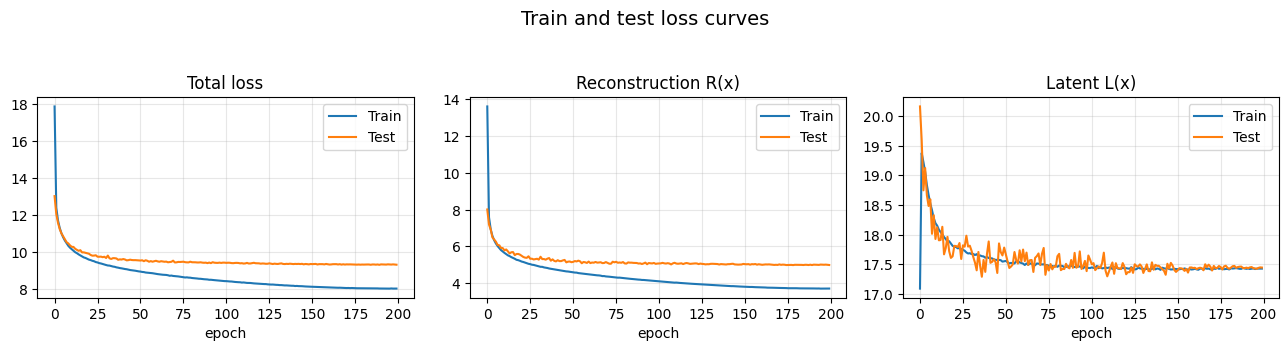

In [23]:
# Loss curves visualization
if history:
    plot_loss_curves(history, save_path=f"{CVAE_DIR}/cvae_loss_curves.png", show=True)
else:
    print("No training history available for this checkpoint.")

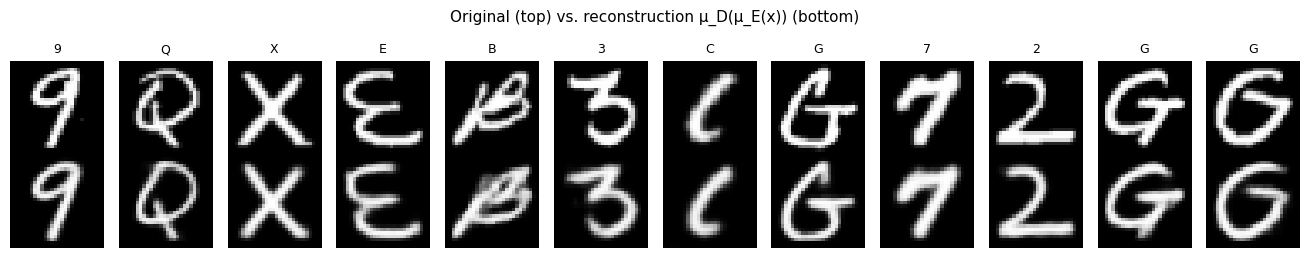

In [24]:
x_vis, y_vis = next(iter(test_dl))
plot_reconstructions(trained_model, x_vis, y_vis, save_path=f"{CVAE_DIR}/cvae_reconstructions.png", conditional=True, show=True)

**Prior samples with label conditioning (no flow).** We decode $z \sim \mathcal{N}(0, I)$ with labels cycling through `0…Z`. Because class identity now comes from $y$, almost every sample is the **correct, legible character**. This is a large improvement over the unconditional baseline in Section 4.2.

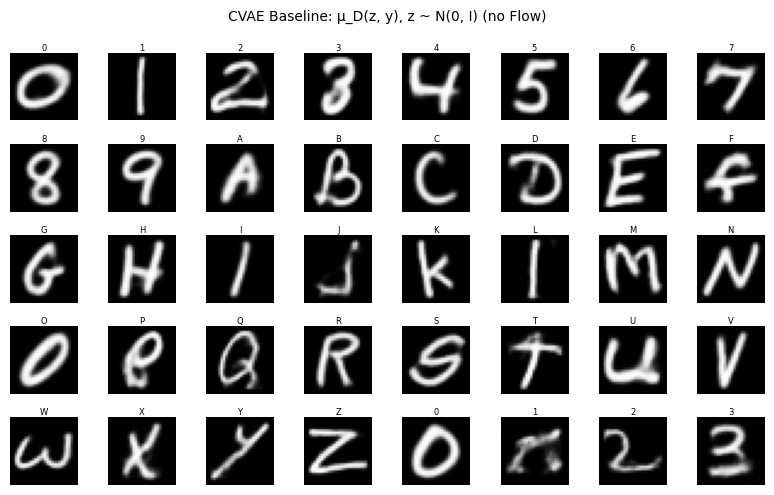

In [25]:
plot_prior_samples_cvae(trained_model, 40, save_path=f"{CVAE_DIR}/cvae_priors_with_label_signal.png", show=True)

**Interpolation (CVAE).** We interpolate **both** the latent $z$ and the decoder's class embedding between two test images. The morph between two *different* classes (e.g. `9 → Q`) shows that the learned class embeddings are also arranged smoothly.

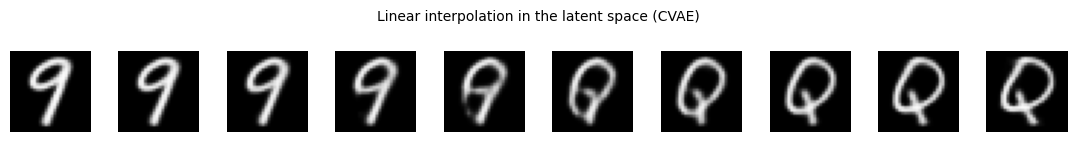

In [26]:
plot_interpolation_cvae(trained_model, x_vis[0], x_vis[1], y_vis[0], y_vis[1], steps=10, save_path=f"{CVAE_DIR}/interpolation_in_latent_space.png", show=True)

**Latent space (PCA).** Here is the key difference from Section 4.2: **all class centroids collapse to the origin**, and the classes are fully mixed. The CVAE latent is (almost) **class-independent**: it encodes *style*, not *identity*. This is why an **unconditional** flow over $z$ works for class-controlled generation.

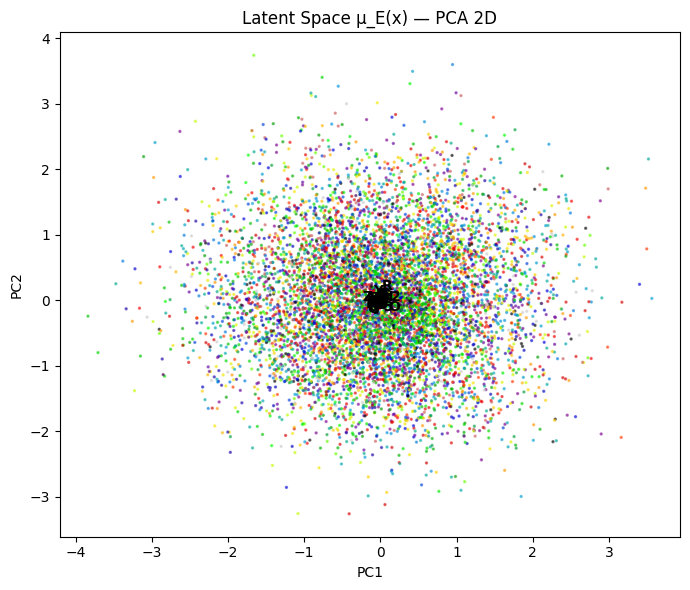

In [27]:
plot_latent_pca(latents["test"]["mu"], latents["test"]["y"], save_path=f"{CVAE_DIR}/cvae_latent_pca.png", show=True)

---
# 7. Stage 2: Latent Rectified Flow

## 7.1 Theory

We want to sample from the distribution of CVAE latents $p_{\text{data}}(x_0)$, where each $x_0 = \mu_E(x, y) \in \mathbb{R}^{16}$. **Rectified flow** (a form of flow matching) connects data and noise with **straight lines**:

$$\tilde{x}_t = (1 - t)\,x_0 + t\,h, \qquad h \sim \mathcal{N}(0, I),\quad t \sim \mathcal{U}[0, 1]$$

so that $t = 0$ is data and $t = 1$ is pure noise. Along each line the velocity is constant, $\frac{d\tilde{x}_t}{dt} = h - x_0$. We train a network to regress it:

$$\mathcal{L}(\theta) = \mathbb{E}_{x_0, h, t}\Big[\big\lVert v_\theta(\tilde{x}_t, t) - (h - x_0)\big\rVert^2\Big]$$

> **Note on the convention:** the assignment uses the opposite direction ($z(0) \sim \mathcal{N}(0, I)$ is noise, $z(1) = \mu_E(x)$ is data). Both describe the same straight line under $t \to 1 - t$: our velocity $h - x_0$ is the negative of the assignment's $z(1) - z(0)$, which is why we integrate backwards here. Section 9 follows the assignment's convention exactly.

**Generation** solves the ODE $\frac{dx}{dt} = v_\theta(x, t)$ **backwards** from $t=1$ (a noise sample) to $t=0$ (a latent code). Two solvers are implemented:

- **Euler** (1st order): $x \leftarrow x - \Delta t\, v_\theta(x, t)$
- **Heun** (2nd order, predictor–corrector): an Euler step predicts $x'$, then the update averages the velocity at both ends:
  $x \leftarrow x - \tfrac{\Delta t}{2}\big[v_\theta(x, t) + v_\theta(x', t - \Delta t)\big]$.
  It is more accurate per step, so **25 Heun steps cost the same (50 network evaluations) as 50 Euler steps**, with a smaller discretization error.

**Why the loss does not go to zero.** Many pairs $(x_0, h)$ pass through the same point $\tilde{x}_t$, so the target $h - x_0$ is *random* given $(\tilde x_t, t)$. The best possible predictor is the conditional mean $\mathbb{E}[h - x_0 \mid \tilde{x}_t]$, and the remaining variance is an irreducible floor. A useful reference point: a network that always outputs 0 would score $\mathbb{E}\lVert h - x_0\rVert^2 / 16 \approx 1 + \operatorname{Var}(x_0) \approx 1 + 0.87^2 \approx 1.76$ (per-dimension MSE). Our model reaches ≈ **1.32**.

**Why not normalize the latents?** Flow matching works best when data and noise have similar scales. The CVAE latents already have mean ≈ 0 and std ≈ 0.87 thanks to the KL term, so no extra normalization is needed. `mu_mean`/`mu_std` are saved but not used.

## 7.2 Velocity network architecture

The data are 16‑D vectors (not images), so the velocity field is a **residual MLP**, not a U‑Net:

| Component | Details | Why |
|---|---|---|
| `SinusoidalTimeEmbedding` | $t \mapsto [\sin(t\,\omega_k), \cos(t\,\omega_k)]$, 32‑D, frequencies geometrically spaced up to $10^4$ | A raw scalar $t$ is a weak input. Multi-frequency features let the network change its behavior sharply across time, as in Transformers and diffusion models |
| Input projection | Concat $[x_t, \text{emb}(t)]$ (16+32) → Linear → 128 | |
| 3 × `ResBlock1D` | Pre-norm: LayerNorm → SiLU → Linear → LayerNorm → SiLU → Linear, plus skip connection | Skip connections give a clean gradient path. **LayerNorm** (not BatchNorm) normalizes each sample on its own, which suits a regression where every sample has a different $t$ |
| Output head | LayerNorm → SiLU → Linear → 16 | Predicts the velocity in latent space |

**Hidden size 128 with 3 blocks** (~110k parameters) is plenty for a 16‑D distribution. A much larger network would mostly fit the irreducible noise in the target.

`RectifiedFlow` wraps the network with the loss (`compute_loss`) and the sampler (`sample`).

In [28]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class SinusoidalTimeEmbedding(nn.Module):
    """Maps scalar t in [0, 1] to a higher-dimensional frequency representation."""
    def __init__(self, dim: int = 32):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        t = t.view(-1, 1)
        half_dim = self.dim // 2
        freqs = torch.exp(
            -math.log(10000.0) * torch.arange(half_dim, device=t.device, dtype=t.dtype) / half_dim
        )
        args = t * freqs.unsqueeze(0)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class ResBlock1D(nn.Module):
    """Residual block for low-dimensional vector velocity fields."""
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.block(x)


class VelocityNet(nn.Module):
    """Parametrizes v_theta(x_tilde, t) for 16D inputs."""
    def __init__(self, data_dim: int = 16, time_dim: int = 32, hidden_dim: int = 128, num_blocks: int = 3):
        super().__init__()
        self.time_embed = SinusoidalTimeEmbedding(time_dim)
        self.in_proj = nn.Linear(data_dim + time_dim, hidden_dim)
        self.blocks = nn.ModuleList([ResBlock1D(hidden_dim) for _ in range(num_blocks)])
        self.out_proj = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, data_dim),
        )

    def forward(self, x_tilde: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_embed(t)                          # (B, time_dim)
        h = torch.cat([x_tilde, t_emb], dim=-1)             # (B, data_dim + time_dim)
        h = self.in_proj(h)
        for block in self.blocks:
            h = block(h)
        return self.out_proj(h)                             # (B, data_dim)

class RectifiedFlow(nn.Module):
    def __init__(self, model: nn.Module, data_dim: int = 16):
        super().__init__()
        self.model = model
        self.data_dim = data_dim

    def compute_loss(
        self,
        x0: torch.Tensor,
        generator: torch.Generator | None = None,
        return_per_sample: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        batch_size = x0.shape[0]
        device = x0.device

        # 1. Sample t ~ Uniform(0, 1) and noise h ~ N(0, I)
        t = torch.rand((batch_size,), generator=generator, device=device, dtype=x0.dtype)
        h = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)

        # 2. Straight-line interpolant: x_tilde = (1 - t) * x0 + t * h
        t_col = t.unsqueeze(-1)
        x_tilde = (1.0 - t_col) * x0 + t_col * h

        # 3. Predict velocity and compute MSE against (h - x0)
        v_pred = self.model(x_tilde, t)
        per_sample_mse = (v_pred - (h - x0)).pow(2).mean(dim=-1)  # (B,)

        if return_per_sample:
            return per_sample_mse, t
        return per_sample_mse.mean()

    @torch.no_grad()
    def sample(
        self,
        num_samples: int,
        num_steps: int = 50,
        method: str = "heun",
        device: torch.device | str = "cpu",
    ) -> torch.Tensor:
        """
        Integrates dx/dt = v_theta(x, t) backward from t = 1 (noise) to t = 0 (data).
        """
        self.model.eval()
        x = torch.randn(num_samples, self.data_dim, device=device)

        # Descending time grid: [1.0, ..., 0.0]
        ts = torch.linspace(1.0, 0.0, num_steps + 1, device=device)

        for i in range(num_steps):
            t_curr = ts[i]
            t_next = ts[i + 1]
            dt = t_curr - t_next  # positive step size: 1 / num_steps

            t_batch = torch.full((num_samples,), t_curr, device=device)
            v1 = self.model(x, t_batch)

            if method == "euler":
                # 1st-order backward step
                x = x - dt * v1

            elif method == "heun":
                # Predictor (Euler)
                x_pred = x - dt * v1
                # Corrector (evaluate velocity at predicted endpoint t_next)
                t_next_batch = torch.full((num_samples,), t_next, device=device)
                v2 = self.model(x_pred, t_next_batch)
                x = x - 0.5 * dt * (v1 + v2)

            else:
                raise ValueError(f"Unknown ODE solver '{method}'. Use 'euler' or 'heun'.")

        return x

## 7.3 Training utilities

**`train_velocity_field`**

- **AdamW + cosine annealing down to `eta_min=1e-5`.** The LR does not reach exactly 0, so late epochs still make small refinements.
- **Gradient clipping (`max_norm=1.0`).** The regression target $h - x_0$ is noisy and can occasionally produce large gradients. Clipping stops these from destabilizing training.
- **Fixed validation generator (seed 42).** Every epoch is validated with the *same* $(t, h)$ draws, so changes in validation loss reflect the model and not sampling noise.
- **Low-noise metric `val_loss_low_t` ($t \le 0.2$).** This is the final stretch of sampling, where the exact latent (and therefore the fine details of the character) is decided. It is worth tracking separately.
- **Best-weights restore**, the same as for the VAE.

**`get_latent_dataloaders`** wraps the saved `latents.pt` (posterior means $\mu_E$ and labels) in `DataLoader`s. The labels are loaded but **not used** by the flow, which is unconditional by design (see Section 2.3).

In [29]:
from pathlib import Path
import copy
from tqdm import tqdm

def train_velocity_field(
    flow: RectifiedFlow,
    train_loader: DataLoader,
    val_loader: DataLoader | None = None,
    epochs: int = 80,
    optimizer: torch.optim.Optimizer | None = None,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    grad_clip: float = 1.0,
    device: torch.device | str = "cuda",
) -> dict[str, list[float]]:
    flow.to(device)
    if optimizer is None:
        optimizer = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    history = {"train_loss": [], "val_loss": [], "val_loss_low_t": []}
    best_val_loss = float("inf")
    best_weights = None

    for epoch in range(1, epochs + 1):
        # --- Train ---
        flow.train()
        running_loss, total_samples = 0.0, 0

        for batch in train_loader:
            x0 = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(device)
            loss = flow.compute_loss(x0)

            optimizer.zero_grad()
            loss.backward()
            if grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(flow.parameters(), max_norm=grad_clip)
            optimizer.step()

            running_loss += loss.item() * x0.shape[0]
            total_samples += x0.shape[0]

        scheduler.step()
        epoch_train_loss = running_loss / total_samples
        history["train_loss"].append(epoch_train_loss)

        # --- Validate ---
        if val_loader is not None:
            flow.eval()
            val_gen = torch.Generator(device=device).manual_seed(42)
            val_running, low_t_running = 0.0, 0.0
            val_samples, low_t_samples = 0, 0

            with torch.no_grad():
                for batch in val_loader:
                    x0 = (batch[0] if isinstance(batch, (list, tuple)) else batch).to(device)
                    per_sample_mse, t = flow.compute_loss(
                        x0, generator=val_gen, return_per_sample=True
                    )

                    val_running += per_sample_mse.sum().item()
                    val_samples += x0.shape[0]

                    low_t_mask = t <= 0.2
                    if low_t_mask.any():
                        low_t_running += per_sample_mse[low_t_mask].sum().item()
                        low_t_samples += int(low_t_mask.sum().item())

            epoch_val_loss = val_running / val_samples
            epoch_low_t_loss = low_t_running / max(low_t_samples, 1)

            history["val_loss"].append(epoch_val_loss)
            history["val_loss_low_t"].append(epoch_low_t_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(flow.state_dict())

            if epoch % 10 == 0 or epoch == 1:
                print(
                    f"Epoch {epoch:03d}/{epochs:03d} | "
                    f"Train MSE: {epoch_train_loss:.5f} | "
                    f"Val MSE: {epoch_val_loss:.5f} | "
                    f"Val MSE (t<=0.2): {epoch_low_t_loss:.5f}"
                )
        elif epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:03d}/{epochs:03d} | Train MSE: {epoch_train_loss:.5f}")

    if best_weights is not None:
        flow.load_state_dict(best_weights)

    return history

def save_flow_checkpoint(
    flow: RectifiedFlow,
    save_path: str,
    config: dict | None = None,
    history: dict | None = None,
) -> None:
    # weights as .safetensors; architecture config and loss history in the metadata
    save_model(flow.state_dict(), str(save_path),
               {"data_dim": flow.data_dim, "config": config or {}, "history": history})


def load_flow_checkpoint(
    checkpoint_path: str,
    device: torch.device | str = "cuda",
) -> tuple[RectifiedFlow, dict]:
    state_dict, ckpt = load_model_file(str(checkpoint_path), device)  # .safetensors or legacy .pt
    cfg = ckpt.get("config", {})

    model = VelocityNet(
        data_dim=ckpt.get("data_dim", 16),
        time_dim=cfg.get("time_dim", 32),
        hidden_dim=cfg.get("hidden_dim", 128),
        num_blocks=cfg.get("num_blocks", 3),  # default matches the architecture used in Section 7.4
    )
    flow = RectifiedFlow(model=model, data_dim=ckpt.get("data_dim", 16))
    flow.load_state_dict(state_dict)
    flow.to(device).eval()

    return flow, ckpt

In [30]:
import torch
from torch.utils.data import DataLoader, TensorDataset


def get_latent_dataloaders(
    latents_path: str,
    batch_size: int = 256,
    test_batch_size: int = 512,
) -> tuple[DataLoader, DataLoader]:
    data = torch.load(latents_path, map_location="cpu")

    train_dict = data["train"]
    test_dict = data["test"]

    train_dataset = TensorDataset(
        train_dict["mu"].float(),
        train_dict["y"].long(),
    )
    test_dataset = TensorDataset(
        test_dict["mu"].float(),
        test_dict["y"].long(),
    )

    use_pin_memory = torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=use_pin_memory,
        drop_last=True,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=test_batch_size,
        shuffle=False,
        pin_memory=use_pin_memory,
    )

    return train_loader, test_loader

## 7.4 Training the flow

| Hyperparameter | Value | Rationale |
|---|---|---|
| Training data | CVAE latents `./cvae/latents.pt` | The final model pairs this flow with the CVAE decoder |
| `epochs` | 200 | Each epoch is cheap (86k 16‑D vectors). The loss keeps improving slowly, and the fresh random $(t, h)$ every epoch acts as data augmentation |
| `batch_size` | 256 | |
| Optimizer | AdamW, `lr=1e-3` | Created outside the training function with the default `weight_decay` (0.01), so the function's `weight_decay=1e-4` argument is not used here |
| Time embedding / hidden / blocks | 32 / 128 / 3 | See Section 7.2 |

The trained flow is saved to `FLOW_DIR/flow_model.safetensors` together with its architecture config and loss history (in the file's metadata). With `TRAIN_FLOW = False`, it is loaded instead, from `BASE_DIR` or else `FLOW_DIR`.

In [31]:
# FLOW PARAMETERS
latent_dim = 16
epochs = 200
batch_size = 256
lr = 1e-3
FLOW_CONFIG = {"time_dim": 32, "hidden_dim": 128, "num_blocks": 3}
FLOW_CKPT = os.path.join(FLOW_DIR, "flow_model.safetensors")   # where a newly trained flow is saved

# The flow is trained on the CVAE latents exported in Section 6
train_loader, test_loader = get_latent_dataloaders(os.path.join(CVAE_DIR, "latents.pt"), batch_size=batch_size)

if TRAIN_FLOW:
    model = VelocityNet(data_dim=latent_dim, **FLOW_CONFIG).to(device)
    flow = RectifiedFlow(model=model, data_dim=latent_dim)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = train_velocity_field(flow, train_loader, test_loader, epochs, optimizer, lr, device=device)
    # Save the architecture config too, so load_flow_checkpoint() can rebuild the exact same network
    save_flow_checkpoint(flow, save_path=FLOW_CKPT, config=FLOW_CONFIG, history=history)
    print(f"Flow saved to {FLOW_CKPT}")
else:
    flow_path = find_checkpoint("flow_model", FLOW_DIR)   # BASE_DIR first, then FLOW_DIR
    flow, flow_ckpt = load_flow_checkpoint(flow_path, device=device)
    history = flow_ckpt.get("history")
    print(f"Loaded flow from {flow_path}")

Loaded flow from ./flow_model.safetensors


**Quick check: Euler vs Heun.** Both solvers produce 16‑D latents. Heun uses half as many steps for the same compute (see Section 7.1).

In [32]:
# Generate samples with Euler vs. Heun
samples_euler = flow.sample(num_samples=64, num_steps=50, method="euler", device=device)
samples_heun = flow.sample(num_samples=64, num_steps=25, method="heun", device=device)
print(f"Euler shape: {samples_euler.shape} | Heun shape: {samples_heun.shape}")

Euler shape: torch.Size([64, 16]) | Heun shape: torch.Size([64, 16])


## 7.5 Diagnostics

**Loss curves.** The validation MSE decreases from 1.39 to ≈ 1.32 and then flattens near the irreducible floor described in Section 7.1. The low-noise regime ($t \le 0.2$) has a lower MSE (≈ 1.19) and keeps improving slowly throughout training. Train and validation curves overlap, so there is no overfitting.

In [33]:
from IPython.display import display
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def plot_loss_history(
    history: dict[str, list[float]],
    save_path: str = "flow_loss_history.png",
    title: str = "Rectified Flow Training & Test Loss",
    show: bool = True,
) -> plt.Figure:
    train_loss = history.get("train_loss", [])
    val_loss = history.get("val_loss", [])
    low_t_loss = history.get("val_loss_low_t", [])

    epochs = np.arange(1, len(train_loss) + 1)
    has_low_t = len(low_t_loss) > 0

    ncols = 2 if has_low_t else 1
    fig, axes = plt.subplots(1, ncols, figsize=(6.5 * ncols, 4.5), constrained_layout=True)
    if ncols == 1:
        axes = [axes]

    ax = axes[0]
    ax.plot(epochs, train_loss, label="Train MSE", linewidth=2.0, color="#1f77b4")

    if len(val_loss) > 0:
        ax.plot(epochs, val_loss, label="Test MSE", linewidth=2.0, color="#ff7f0e")
        best_idx = int(np.argmin(val_loss))
        ax.axvline(
            epochs[best_idx],
            color="#ff7f0e",
            linestyle="--",
            alpha=0.6,
            label=f"Best Test (ep {epochs[best_idx]}: {val_loss[best_idx]:.4f})",
        )

    ax.set_title("Overall Velocity MSE")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(frameon=True)

    if has_low_t:
        ax_low = axes[1]
        ax_low.plot(
            epochs,
            low_t_loss,
            label="Test MSE (t <= 0.2)",
            linewidth=2.0,
            color="#2ca02c",
        )
        best_low_idx = int(np.argmin(low_t_loss))
        ax_low.scatter(
            epochs[best_low_idx],
            low_t_loss[best_low_idx],
            color="#2ca02c",
            zorder=5,
            label=f"Min (ep {epochs[best_low_idx]}: {low_t_loss[best_low_idx]:.4f})",
        )
        ax_low.set_title("Low-Noise Regime MSE (t <= 0.2)")
        ax_low.set_xlabel("Epoch")
        ax_low.set_ylabel("MSE Loss")
        ax_low.grid(True, linestyle=":", alpha=0.5)
        ax_low.legend(frameon=True)

    fig.suptitle(title, fontsize=13)

    if save_path and SAVE_FIGURES:   # SAVE_FIGURES is set in Section 0
        out_file = Path(save_path)
        out_file.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_file, dpi=300, bbox_inches="tight")

    if show:
        display(fig)  # plt.show() does nothing here: Section 3.2 switches matplotlib to the Agg backend
    plt.close(fig)

    return fig

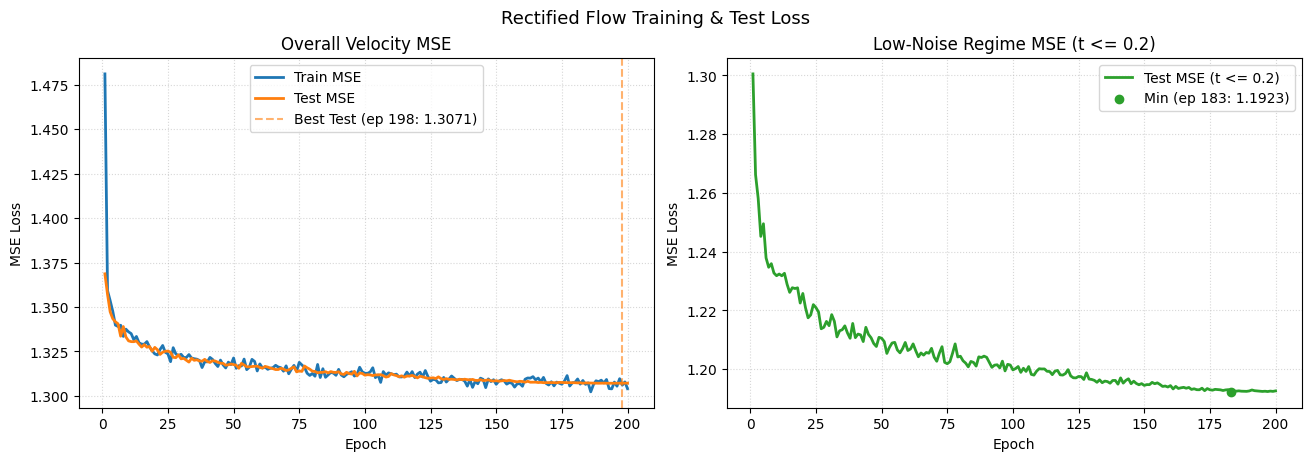

In [34]:
if history:
    plot_loss_history(history, save_path=f"{FLOW_DIR}/loss_curves.png", show=True)
else:
    print("No training history available for this checkpoint.")

**Velocity field and trajectories.** We project the 16‑D latent space onto its first two principal components (fitted on real latents, shown in gray). For several times $t$ we plot:

- **Arrows:** the reverse velocity $-v_\theta(x, t)$ evaluated on a 2D grid. The grid points are lifted back to 16‑D with the remaining principal components set to 0. Color shows speed.
- **Red dots and trails:** 80 particles integrated with Heun from $t=1$ to the displayed time.

How to read it: far from the data the arrows point **inward** with high speed, pulling outlying noise toward the data. Near the data the field is weak. The particles end up spread across the support of the real latents rather than collapsing to a point, which shows the flow is preserving diversity. Keep in mind this is a 2D slice of a 16‑D field, so it shows only part of the dynamics.

In [35]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display


@torch.no_grad()
def plot_velocity_fields(
    flow,
    real_data: torch.Tensor,
    plot_times: list[float] = [1.0, 0.75, 0.5, 0.25, 0.05],
    num_samples: int = 80,
    num_steps: int = 40,
    method: str = "heun",
    grid_res: int = 20,
    save_path: str = None,
    device: torch.device | str = "cuda",
):
    """
    Visualizes the 16D learned velocity field -v_theta(x, t) and particle trajectories
    projected onto the top 2 principal components of `real_data` at chosen timesteps.
    """
    flow.eval()
    flow.to(device)

    # 1. Fit 2D PCA on real 16D data to define the viewing plane
    real_np = real_data.detach().cpu().numpy()
    pca = PCA(n_components=2)
    real_2d = pca.fit_transform(real_np)

    # Build a 2D grid covering the real data + initial Gaussian noise range
    bound = max(np.abs(real_2d).max() * 1.3, 3.0)
    lin = np.linspace(-bound, bound, grid_res)
    xx, yy = np.meshgrid(lin, lin)
    grid_2d = np.column_stack([xx.ravel(), yy.ravel()])          # (G^2, 2)

    # Lift 2D grid points back to 16D (PCs 3..16 set to 0)
    grid_16d = torch.tensor(
        pca.inverse_transform(grid_2d), dtype=torch.float32, device=device
    )

    # 2. Run ODE sampling and store particle positions at every step
    x = torch.randn(num_samples, flow.data_dim, device=device)
    ts = torch.linspace(1.0, 0.0, num_steps + 1, device=device)
    trajectory = [x.cpu().numpy()]

    for i in range(num_steps):
        t_curr, t_next = ts[i], ts[i + 1]
        dt = t_curr - t_next

        v1 = flow.model(x, torch.full((num_samples,), t_curr, device=device))
        if method == "euler":
            x = x - dt * v1
        elif method == "heun":
            x_pred = x - dt * v1
            v2 = flow.model(x_pred, torch.full((num_samples,), t_next, device=device))
            x = x - 0.5 * dt * (v1 + v2)
        else:
            raise ValueError(f"Unknown solver '{method}'. Use 'euler' or 'heun'.")

        trajectory.append(x.cpu().numpy())

    # Project full trajectories (steps + 1, num_samples, 16) -> (steps + 1, num_samples, 2)
    traj_2d = np.stack([pca.transform(step_x) for step_x in trajectory], axis=0)

    # 3. Plot each requested snapshot
    fig, axes = plt.subplots(1, len(plot_times), figsize=(4.5 * len(plot_times), 4.5), sharex=True, sharey=True)
    if len(plot_times) == 1:
        axes = [axes]

    for ax, target_t in zip(axes, plot_times):
        # Match the closest discrete solver timestep
        step_idx = int(torch.argmin(torch.abs(ts - target_t)).item())
        t_val = float(ts[step_idx].item())

        # Evaluate velocity field on the 2D slice (negated for sampling direction t: 1 -> 0)
        t_grid = torch.full((grid_16d.shape[0],), t_val, device=device)
        v_16d = -flow.model(grid_16d, t_grid).cpu().numpy()

        # Project displacement vectors without mean subtraction
        v_2d = v_16d @ pca.components_.T
        u = v_2d[:, 0].reshape(grid_res, grid_res)
        w = v_2d[:, 1].reshape(grid_res, grid_res)
        speed = np.hypot(u, w)

        # Background: real data distribution
        ax.scatter(real_2d[:, 0], real_2d[:, 1], s=6, alpha=0.15, color="gray", label="Real data")

        # Vector field arrows
        q = ax.quiver(xx, yy, u, w, speed, cmap="viridis", alpha=0.85, pivot="mid")

        # Particle trails up to step_idx + current particle positions
        if step_idx > 0:
            for p in range(min(num_samples, 25)):
                ax.plot(
                    traj_2d[: step_idx + 1, p, 0],
                    traj_2d[: step_idx + 1, p, 1],
                    color="crimson",
                    alpha=0.25,
                    linewidth=0.9,
                )
        ax.scatter(
            traj_2d[step_idx, :, 0],
            traj_2d[step_idx, :, 1],
            s=18,
            color="crimson",
            edgecolors="white",
            linewidths=0.4,
            label="Samples",
        )

        ax.set_title(f"t = {t_val:.2f}")
        ax.set_xlabel("PC 1")
        ax.set_xlim(-bound, bound)
        ax.set_ylim(-bound, bound)

    axes[0].set_ylabel("PC 2")
    axes[0].legend(loc="upper right", frameon=True, fontsize=8)
    fig.colorbar(q, ax=axes, fraction=0.015, pad=0.02, label="Velocity magnitude ||v||")
    fig.suptitle(f"Learned Reverse Velocity Field & Trajectories ({method.upper()})", y=1.03)
    if save_path is not None and SAVE_FIGURES:   # SAVE_FIGURES is set in Section 0
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    display(fig)
    plt.close(fig)
    return fig

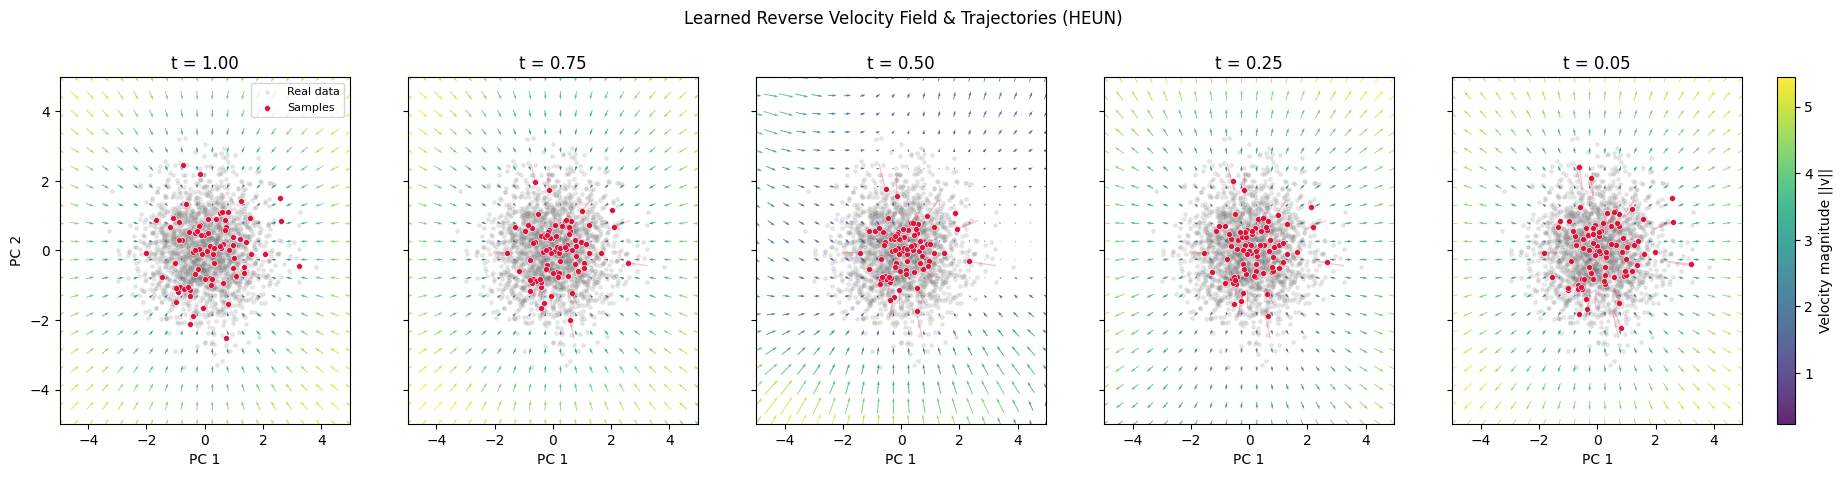

In [36]:
real_data = test_loader.dataset.tensors[0]

fig = plot_velocity_fields(
    flow=flow,
    real_data=real_data[:2000],
    plot_times=[1.0, 0.75, 0.5, 0.25, 0.05],
    num_samples=80,
    num_steps=40,
    method="heun",
    grid_res=20,
    save_path=f"{FLOW_DIR}/flow_visualization.png",
    device=device,
)

---
# 8. Full generation: latent flow + conditional decoder

This is the complete model:

1. Sample $h \sim \mathcal{N}(0, I_{16})$.
2. Integrate the flow ODE from $t=1$ to $t=0$ (**Heun, 50 steps**) to get a style latent $z$.
3. Choose a class $y$ and decode: $\hat{x} = \mu_D(z, y)$.

Compare the result with the CVAE prior samples in Section 6.1. The flow replaces $z \sim \mathcal{N}(0, I)$ with $z$ drawn from the *learned* latent distribution. Most characters are clean and varied in style. A few classes (e.g. some `I`, `D`, `W` samples) still show artifacts; these come from rare styles and from the decoder's limits.

In [37]:
@torch.no_grad()
def generate_data_samples(cvae: CVAE, flow: RectifiedFlow, n: int = 64, seed: int | None = None, save_path=None, y=None, show=True):
    cvae.eval()
    flow.eval()
    device = next(cvae.parameters()).device
    if seed is not None:
        torch.manual_seed(seed)  # seeds CPU and CUDA, so flow.sample() below draws the same noise

    labels_list = []
    if y is None:
        for i in range(n):
            labels_list.append(i % cvae.num_classes)
    else:
        y = char_to_idx[y]
        for i in range(n):
            labels_list.append(int(y))

    y = torch.tensor(labels_list, dtype=torch.long, device=device)
    z = flow.sample(num_samples=n, num_steps=50, method="heun", device=device)

    imgs = cvae.decode(z, y).cpu()

    cols = 8
    fig, axes = plt.subplots(n // cols, cols, figsize=(cols * 1.0, n // cols * 1.0))
    for i, (ax, img) in enumerate(zip(axes.flat, imgs)):
        ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        # Optional: display the class name or index as a tiny title
        cls_idx = int(y[i].item())
        ax.set_title(idx_to_char[cls_idx], fontsize=6, pad=1)

    fig.suptitle("CVAE with Rectified Flow in Latent Space", fontsize=10)
    _finish(fig, save_path, show)

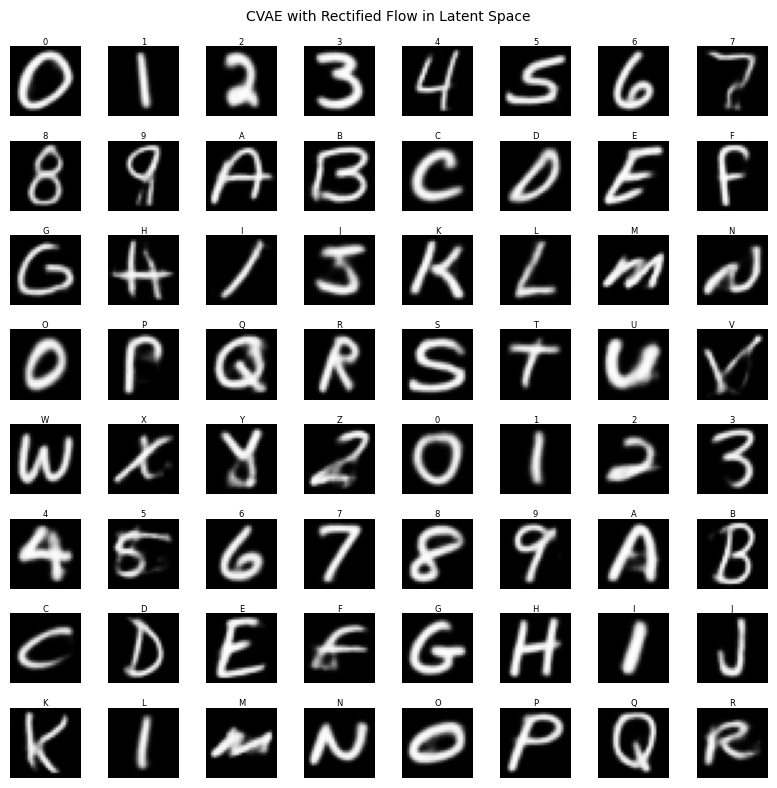

In [38]:
generate_data_samples(trained_model, flow, n=64, seed=32, save_path=f"{FLOW_DIR}/final_samples.png", show=True)

---
# 9. Bonus (+5): Class-conditional flow + Classifier-Free Guidance

In Section 8, class control came from the **CVAE decoder**, while the velocity field $v_\theta(x, t)$ was unconditional.
The assignment bonus (Part 7) asks for the conditioning signal **inside the flow**, $\Phi(z, t, c)$, plus
**Classifier-Free Guidance (CFG)** at sampling time.

**Setup.** We use the latents of the **unconditional VAE** (Section 4, `VAE_DIR/latents.pt`): there the class
information lives in $z$ itself (see its PCA), so the flow alone must steer each sample to the right class region,
and the plain VAE decoder $\mu_D(z)$ turns it into an image.
Note: this section follows the **course convention** (forward parametrization, noise at $t=0$), the opposite
time direction of Section 7:

- $z(0) \sim \mathcal{N}(0, I)$ (noise), $\; z(1) = \mu_E(x)$ (data, standardized per dimension)
- $z(t) = (1-t)\,z(0) + t\,z(1)$, target velocity $z(1) - z(0)$
- $c \in \{0, \dots, 35\}$, plus a **null token** $\varnothing = 36$

**Training (label dropout).** With probability $p_{\text{uncond}} = 0.15$ the label is replaced by $\varnothing$, so a single
network learns both $\Phi(z, t, c)$ and $\Phi(z, t, \varnothing)$:
$$\min_\theta \; \mathbb{E}\,\big\| \Phi(z(t), t, \tilde c;\theta) - (z(1) - z(0)) \big\|^2$$

**Sampling (CFG).** Integrate $dz/dt = v_{\text{CFG}}$ from $t=0$ to $t=1$ (Euler or Heun), with
$$v_{\text{CFG}}(z, t, c) = \Phi(z, t, \varnothing) + w \,\big(\Phi(z, t, c) - \Phi(z, t, \varnothing)\big)$$
$w = 0$ is unconditional, $w = 1$ is plain conditional, $w > 1$ pushes harder towards class $c$.
Finally $x = \mu_D(z(1))$ with the VAE decoder.

## 9.1 Conditional velocity network
Same idea as Section 7.2 (residual MLP + sinusoidal time embedding), with two changes: a **class embedding**
(37 entries: 36 classes + $\varnothing$) added to the time embedding, and **adaLN** blocks, where this
(time + class) vector produces a per-layer scale, shift and gate. The gates start at zero, so each block starts as the identity.

In [39]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class CondSinusoidalEmbedding(nn.Module):
    # Sinusoidal embedding for t in [0, 1]
    def __init__(self, dim: int = 128):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
        args = 1000.0 * t.float()[:, None] * freqs[None, :]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class AdaLNBlock(nn.Module):
    # Residual MLP block modulated (scale/shift/gate) by the (time + class) embedding
    def __init__(self, hidden_dim: int, cond_dim: int):
        super().__init__()
        self.norm = nn.LayerNorm(hidden_dim, elementwise_affine=False)
        self.fc1 = nn.Linear(hidden_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.mod = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 3 * hidden_dim))
        nn.init.zeros_(self.mod[-1].weight)  # starts as identity (adaLN-zero)
        nn.init.zeros_(self.mod[-1].bias)

    def forward(self, h: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:
        scale, shift, gate = self.mod(cond).chunk(3, dim=-1)
        u = self.norm(h) * (1 + scale) + shift
        u = self.fc2(F.silu(self.fc1(F.silu(u))))
        return h + gate * u


class ConditionalVelocityNet(nn.Module):
    # Phi(z, t, c): velocity field conditioned on the class c (36 classes + null token)
    def __init__(self, latent_dim: int = 16, hidden_dim: int = 256, cond_dim: int = 128,
                 num_blocks: int = 4, num_classes: int = 36):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.null_class = num_classes  # index of the null token (unconditional)
        self.time_mlp = nn.Sequential(CondSinusoidalEmbedding(cond_dim), nn.Linear(cond_dim, cond_dim),
                                      nn.SiLU(), nn.Linear(cond_dim, cond_dim))
        self.class_emb = nn.Embedding(num_classes + 1, cond_dim)
        self.in_proj = nn.Linear(latent_dim, hidden_dim)
        self.blocks = nn.ModuleList([AdaLNBlock(hidden_dim, cond_dim) for _ in range(num_blocks)])
        self.out = nn.Sequential(nn.LayerNorm(hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, latent_dim))

    def forward(self, z: torch.Tensor, t: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        cond = self.time_mlp(t) + self.class_emb(c)
        h = self.in_proj(z)
        for block in self.blocks:
            h = block(h, cond)
        return self.out(h)


class CFGRectifiedFlow(nn.Module):
    # Rectified Flow in latent space (t=0 noise -> t=1 data) with Classifier-Free Guidance
    def __init__(self, net: ConditionalVelocityNet, mu_mean: torch.Tensor, mu_std: torch.Tensor):
        super().__init__()
        self.net = net
        self.latent_dim = net.latent_dim
        self.null_class = net.null_class
        # standardization of the latents (z_norm = (mu - mean) / std)
        self.register_buffer("mu_mean", mu_mean.float().clone())
        self.register_buffer("mu_std", mu_std.float().clamp_min(1e-3).clone())

    def normalize(self, mu):
        return (mu - self.mu_mean) / self.mu_std

    def denormalize(self, z):
        return z * self.mu_std + self.mu_mean

    def compute_loss(self, mu: torch.Tensor, y: torch.Tensor, p_uncond: float = 0.15) -> torch.Tensor:
        z1 = self.normalize(mu)                      # data,  t = 1
        z0 = torch.randn_like(z1)                    # noise, t = 0
        t = torch.rand(z1.shape[0], device=z1.device)
        zt = (1 - t[:, None]) * z0 + t[:, None] * z1
        drop = torch.rand(y.shape[0], device=y.device) < p_uncond
        c = torch.where(drop, torch.full_like(y, self.null_class), y)   # label dropout
        return F.mse_loss(self.net(zt, t, c), z1 - z0)

    @torch.no_grad()
    def velocity(self, z, t, c, w: float):
        # v_CFG = Phi(z,t,null) + w * (Phi(z,t,c) - Phi(z,t,null))
        null = torch.full_like(c, self.null_class)
        if w == 0.0:
            return self.net(z, t, null)
        if w == 1.0:
            return self.net(z, t, c)
        v = self.net(torch.cat([z, z]), torch.cat([t, t]), torch.cat([c, null]))
        v_cond, v_uncond = v.chunk(2)
        return v_uncond + w * (v_cond - v_uncond)

    @torch.no_grad()
    def sample(self, labels: torch.Tensor, w: float = 3.0, num_steps: int = 25, method: str = "heun",
               z0: torch.Tensor | None = None, return_trajectory: bool = False):
        # Integrates dz/dt = v_CFG from t=0 to t=1; returns mu_E-scale latents ready for the decoder
        self.net.eval()
        device = self.mu_mean.device
        c = labels.to(device).long()
        z = torch.randn(len(c), self.latent_dim, device=device) if z0 is None else z0.to(device).clone()
        traj = [z.cpu()]
        dt = 1.0 / num_steps
        for i in range(num_steps):
            t = torch.full((len(c),), i * dt, device=device)
            v1 = self.velocity(z, t, c, w)
            if method == "euler":
                z = z + dt * v1
            elif method == "heun":
                z_pred = z + dt * v1
                v2 = self.velocity(z_pred, t + dt, c, w)
                z = z + 0.5 * dt * (v1 + v2)
            else:
                raise ValueError(f"Unknown method '{method}' (use 'euler' or 'heun')")
            if return_trajectory:
                traj.append(z.cpu())
        out = self.denormalize(z)
        return (out, traj) if return_trajectory else out

## 9.2 Training
AdamW + cosine schedule, gradient clipping, and an **EMA** copy of the weights (decay 0.999), which is used for sampling.
The latents are standardized per dimension, and `sample()` undoes this before decoding.
> With `TRAIN_CFG_FLOW = False` (Section 0), the cell below loads `cfg_flow.safetensors` (from `BASE_DIR`, or else `CFG_DIR`) instead of training.

In [40]:
import copy
import time
from pathlib import Path


def train_cfg_flow(flow, train_loader, test_loader, epochs=100, lr=1e-3, p_uncond=0.15,
                   ema_decay=0.999, device="cpu"):
    # Trains Phi(z, t, c) with label dropout; keeps an EMA copy of the weights (used for sampling)
    opt = torch.optim.AdamW(flow.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_loader))
    ema = copy.deepcopy(flow).eval()
    history = {"train_loss": [], "test_loss": []}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        flow.train()
        tot, n = 0.0, 0
        for mu, y in train_loader:
            mu, y = mu.to(device), y.to(device)
            loss = flow.compute_loss(mu, y, p_uncond)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), 1.0)
            opt.step()
            sched.step()
            with torch.no_grad():
                for pe, p in zip(ema.parameters(), flow.parameters()):
                    pe.lerp_(p, 1 - ema_decay)
            tot += loss.item() * len(mu)
            n += len(mu)
        # test loss (fixed seed so epochs are comparable)
        ema.eval()
        g_state = torch.random.get_rng_state()
        torch.manual_seed(0)
        with torch.no_grad():
            te, m = 0.0, 0
            for mu, y in test_loader:
                mu, y = mu.to(device), y.to(device)
                te += ema.compute_loss(mu, y, p_uncond).item() * len(mu)
                m += len(mu)
        torch.random.set_rng_state(g_state)
        history["train_loss"].append(tot / n)
        history["test_loss"].append(te / m)
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f"[{epoch:03d}/{epochs}] train {tot / n:.4f} | test (EMA) {te / m:.4f} | {time.time() - t0:.0f}s")
    return ema, history


def save_cfg_flow(flow, path, config, history):
    # weights (incl. the latent normalization buffers) as .safetensors; config and history in the metadata
    save_model(flow.state_dict(), path, {"config": config, "history": history})


def load_cfg_flow(path, device="cpu"):
    state_dict, ckpt = load_model_file(path, device)   # .safetensors or legacy .pt
    cfg = ckpt["config"]
    net = ConditionalVelocityNet(**cfg)
    flow = CFGRectifiedFlow(net, torch.zeros(cfg["latent_dim"]), torch.ones(cfg["latent_dim"]))
    flow.load_state_dict(state_dict)
    return flow.to(device).eval(), ckpt

In [41]:
# CFG FLOW PARAMETERS
cfg_config = dict(latent_dim=16, hidden_dim=256, cond_dim=128, num_blocks=4, num_classes=36)
cfg_epochs = 100        # ~5 min on CPU, faster on a T4
cfg_batch_size = 512
cfg_lr = 1e-3
p_uncond = 0.15
torch.manual_seed(42)

# Unconditional VAE (Section 4) as decoder + its latents as training data
# (a VAE trained in this session is in VAE_DIR; otherwise look in BASE_DIR first, then VAE_DIR)
vae_path = os.path.join(VAE_DIR, "vae.safetensors") if TRAIN_VAE else find_checkpoint("vae", VAE_DIR)
vae = load_vae(vae_path, device=device)
vae_latents = torch.load(f"{VAE_DIR}/latents.pt", map_location="cpu", weights_only=False)
cfg_train_loader, cfg_test_loader = get_latent_dataloaders(f"{VAE_DIR}/latents.pt", batch_size=cfg_batch_size)

if TRAIN_CFG_FLOW:
    cfg_flow = CFGRectifiedFlow(ConditionalVelocityNet(**cfg_config),
                                vae_latents["mu_mean"], vae_latents["mu_std"]).to(device)
    print(f"Phi(z, t, c): {sum(p.numel() for p in cfg_flow.parameters()) / 1e6:.2f}M parameters")
    cfg_flow, cfg_history = train_cfg_flow(cfg_flow, cfg_train_loader, cfg_test_loader, epochs=cfg_epochs,
                                           lr=cfg_lr, p_uncond=p_uncond, device=device)
    save_cfg_flow(cfg_flow, f"{CFG_DIR}/cfg_flow.safetensors", cfg_config, cfg_history)
else:
    cfg_path = find_checkpoint("cfg_flow", CFG_DIR)   # BASE_DIR first, then CFG_DIR
    cfg_flow, _ckpt = load_cfg_flow(cfg_path, device=device)
    cfg_history = _ckpt["history"]
    print(f"Loaded {cfg_path}")

Loaded ./cfg_flow.safetensors


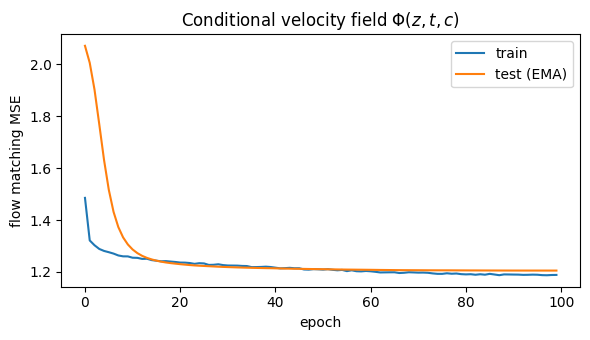

In [42]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(cfg_history["train_loss"], label="train")
ax.plot(cfg_history["test_loss"], label="test (EMA)")
ax.set_xlabel("epoch")
ax.set_ylabel("flow matching MSE")
ax.set_title("Conditional velocity field $\\Phi(z,t,c)$")
ax.legend()
_finish(fig, f"{CFG_DIR}/cfg_loss_curves.png", show=True)

## 9.3 Results

**All 36 classes with CFG.**
Each row is one class; every column starts from a different noise $z(0)$. Heun, 25 steps, $w = 3$.

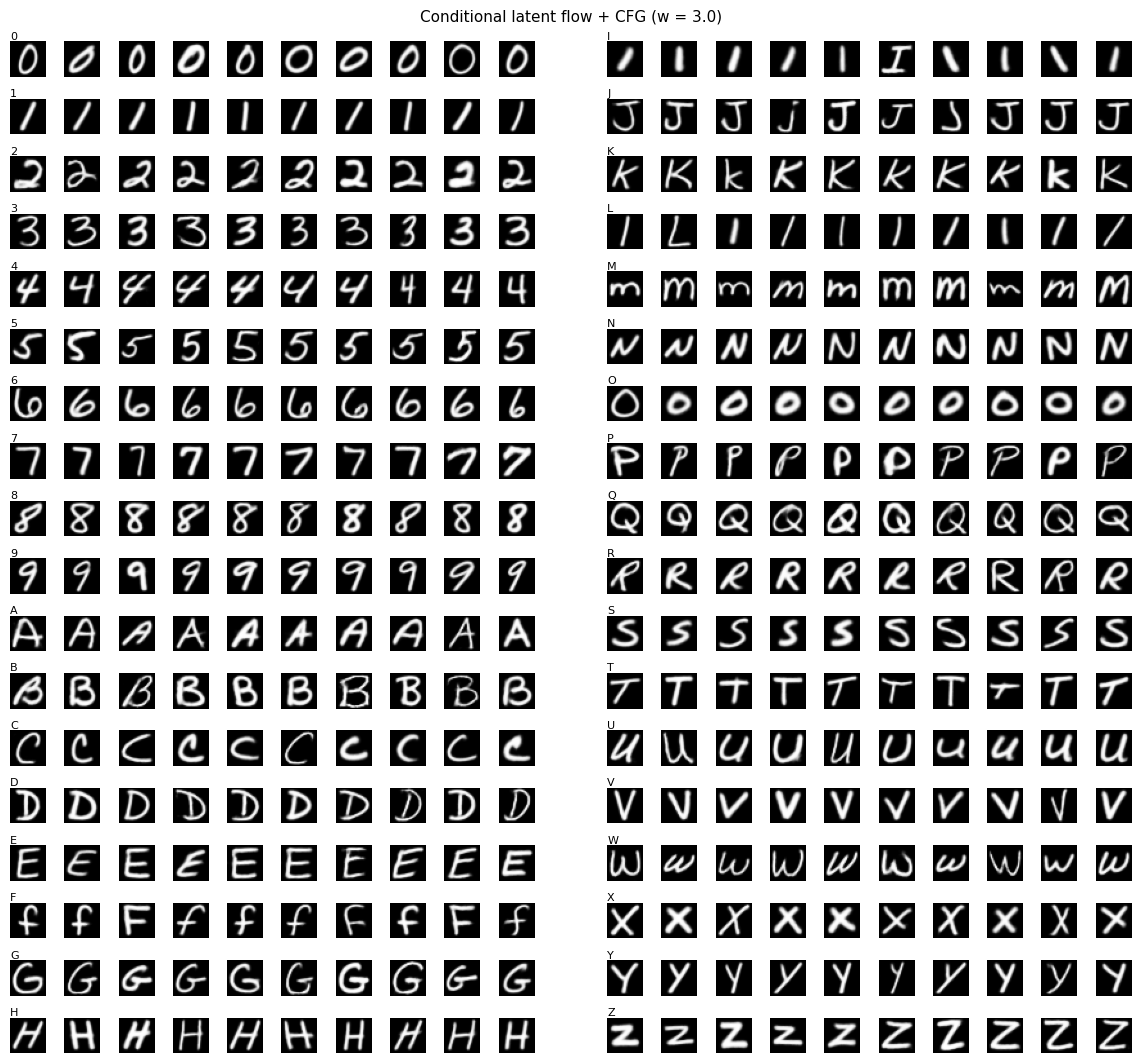

In [43]:
@torch.no_grad()
def generate_cfg(labels, w=3.0, num_steps=25, method="heun", z0=None):
    z1 = cfg_flow.sample(labels, w=w, num_steps=num_steps, method=method, z0=z0)
    return vae.decode(z1).cpu()


def plot_class_grid(w=3.0, per_class=10, seed=0, save_path=None, show=True):
    g = torch.Generator().manual_seed(seed)
    labels = torch.arange(36).repeat_interleave(per_class)
    z0 = torch.randn(len(labels), cfg_config["latent_dim"], generator=g)
    imgs = generate_cfg(labels, w=w, z0=z0)
    # 36 rows x per_class columns, split in two panels of 18 classes for readability
    fig, axes = plt.subplots(18, 2 * per_class + 1, figsize=((2 * per_class + 1) * 0.55, 18 * 0.6))
    for ax in axes.flat:
        ax.axis("off")
    for cls in range(36):
        row, block = cls % 18, cls // 18
        for j in range(per_class):
            col = block * (per_class + 1) + j
            axes[row, col].imshow(imgs[cls * per_class + j, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, block * (per_class + 1)].set_title(CLASS_NAMES[cls], fontsize=8, loc="left", pad=1)
    fig.suptitle(f"Conditional latent flow + CFG (w = {w})", fontsize=11)
    _finish(fig, save_path, show)


plot_class_grid(w=3.0, save_path=f"{CFG_DIR}/cfg_all_classes_w3.png")

**Effect of the guidance scale $w$.**
Same initial noise $z(0)$ for every column; only $w$ changes. $w=0$ ignores the label (unconditional sample),
$w=1$ is the plain conditional field, larger $w$ gives more class-typical (and less diverse) characters.

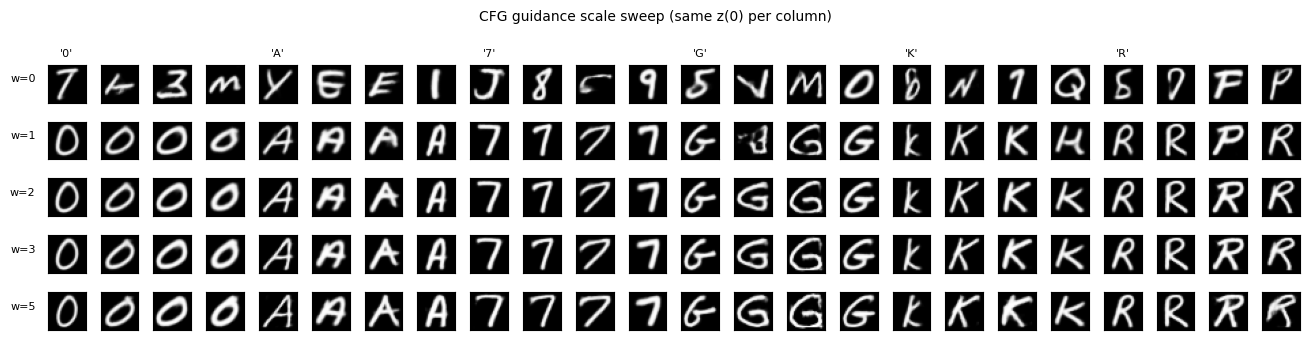

In [44]:
def plot_guidance_sweep(chars="0A7GKR", ws=(0.0, 1.0, 2.0, 3.0, 5.0), per_char=4, seed=1,
                        save_path=None, show=True):
    g = torch.Generator().manual_seed(seed)
    labels = torch.tensor([CLASS_NAMES.index(ch) for ch in chars]).repeat_interleave(per_char)
    z0 = torch.randn(len(labels), cfg_config["latent_dim"], generator=g)
    fig, axes = plt.subplots(len(ws), len(labels), figsize=(len(labels) * 0.55, len(ws) * 0.7))
    for i, w in enumerate(ws):
        imgs = generate_cfg(labels, w=w, z0=z0)
        for j in range(len(labels)):
            ax = axes[i, j]
            ax.imshow(imgs[j, 0], cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(f"w={w:g}", fontsize=8, rotation=0, labelpad=18)
            if i == 0 and j % per_char == 0:
                ax.set_title(f"'{CLASS_NAMES[labels[j]]}'", fontsize=8)
    fig.suptitle("CFG guidance scale sweep (same z(0) per column)", fontsize=10)
    _finish(fig, save_path, show)


plot_guidance_sweep(save_path=f"{CFG_DIR}/cfg_guidance_sweep.png")

**Unconditional pipeline of the assignment (Steps 2–3): $\Phi(z, t, \varnothing)$ + plain VAE decoder.**
With $w = 0$ the network uses only the null token, so this is exactly the unconditional flow of the assignment:
$z(0) \sim \mathcal{N}(0, I)$, integrate $dz/dt = \Phi(z, t, \varnothing)$ from $t=0$ to $t=1$ (Heun, 25 steps), then
$x = \mu_D(z(1))$. Top: VAE alone, decoding $z \sim \mathcal{N}(0, I)$ directly (Section 4.2 baseline). Bottom: the
**same** $z(0)$ transported by the flow before decoding. The flow turns the blurry hybrids into clean characters of random classes.

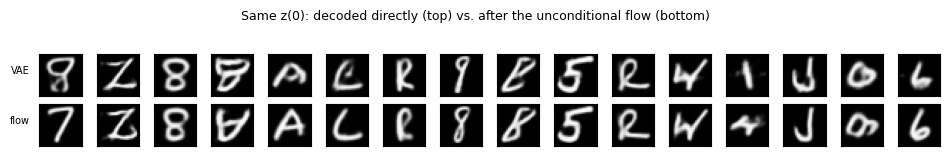

In [45]:
@torch.no_grad()
def plot_flow_vs_prior(n=16, seed=3, save_path=None, show=True):
    g = torch.Generator().manual_seed(seed)
    z0 = torch.randn(n, cfg_config["latent_dim"], generator=g)
    x_prior = vae.decode(z0.to(device)).cpu()                                 # VAE alone: mu_D(z), z ~ N(0, I)
    x_flow = generate_cfg(torch.zeros(n, dtype=torch.long), w=0.0, z0=z0)    # w = 0: label ignored
    fig, axes = plt.subplots(2, n, figsize=(n * 0.6, 1.6))
    for j in range(n):
        for i, img in enumerate((x_prior[j], x_flow[j])):
            axes[i, j].imshow(img[0], cmap="gray", vmin=0, vmax=1)
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[0, 0].set_ylabel("VAE", fontsize=7, rotation=0, labelpad=14)
    axes[1, 0].set_ylabel("flow", fontsize=7, rotation=0, labelpad=14)
    fig.suptitle("Same z(0): decoded directly (top) vs. after the unconditional flow (bottom)", fontsize=9)
    _finish(fig, save_path, show)


plot_flow_vs_prior(save_path=f"{CFG_DIR}/uncond_flow_vs_prior.png")

## 9.4 Quantitative check: does the generated character match the requested class?
We train a small CNN classifier on the real EMNIST-36 training images and use it to classify generated images.
**Class accuracy** = fraction of samples classified as the requested class $c$. We also report the mean
classifier confidence and the pixel-space diversity (mean std across samples of the same class).
Diversity is the pixel std across samples of the *requested* class; at $w=0$ the label is ignored, so those
samples mix several characters and the std is naturally higher.
Note: classes like `0/O`, `1/I`, `5/S`, `2/Z` are naturally confused even for real images, so the
classifier accuracy on the real test set is the practical upper bound.

In [46]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=36):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 256), nn.ReLU(), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.net(x)


def train_classifier(train_loader, test_loader, epochs=3, device="cpu", seed=0):
    torch.manual_seed(seed)   # fixed seed: the "judge" is the same in every run, so the numbers are reproducible
    clf = SmallCNN().to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    for epoch in range(epochs):
        clf.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
    clf.eval()
    correct = n = 0
    with torch.no_grad():
        for x, y in test_loader:
            correct += (clf(x.to(device)).argmax(1).cpu() == y).sum().item()
            n += len(y)
    print(f"Classifier accuracy on real test images: {correct / n:.3f}")
    return clf, correct / n


@torch.no_grad()
def evaluate_generation(w, per_class=100, num_steps=25, method="heun", seed=0):
    torch.manual_seed(seed)
    labels = torch.arange(36).repeat_interleave(per_class)
    imgs = torch.cat([generate_cfg(labels[i:i + 1200], w=w, num_steps=num_steps, method=method)
                      for i in range(0, len(labels), 1200)])
    probs = torch.cat([clf(imgs[i:i + 1200].to(device)).softmax(1).cpu() for i in range(0, len(imgs), 1200)])
    acc = (probs.argmax(1) == labels).float().mean().item()
    conf = probs[torch.arange(len(labels)), labels].mean().item()
    diversity = imgs.view(36, per_class, -1).std(dim=1).mean().item()
    return {"w": w, "method": method, "steps": num_steps, "class_acc": acc, "confidence": conf,
            "diversity": diversity}


clf, real_acc = train_classifier(train_dl, test_dl, epochs=3, device=device)

Classifier accuracy on real test images: 0.903


 sampler steps    w | class acc confidence diversity
    heun    25    0 |     0.029      0.030     0.214
    heun    25    1 |     0.871      0.839     0.175
    heun    25    2 |     0.955      0.932     0.172
    heun    25    3 |     0.966      0.943     0.175
    heun    25    5 |     0.977      0.948     0.182
   euler    10    3 |     0.966      0.946     0.162
   euler    50    3 |     0.967      0.944     0.172
    heun     5    3 |     0.964      0.942     0.173
(classifier on real test images: 0.903)


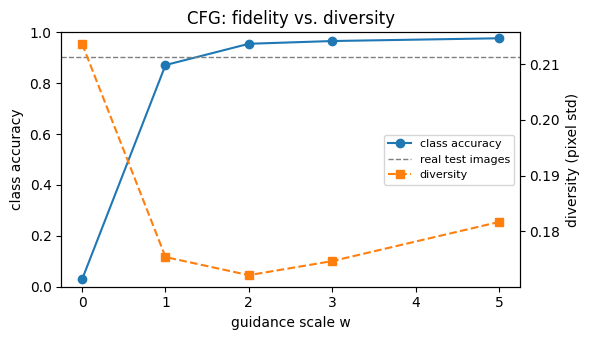

In [47]:
import json

cfg_results = [evaluate_generation(w) for w in (0.0, 1.0, 2.0, 3.0, 5.0)]
cfg_results += [evaluate_generation(3.0, num_steps=s, method=m) for m, s in (("euler", 10), ("euler", 50), ("heun", 5))]

print(f"{'sampler':>8} {'steps':>5} {'w':>4} | {'class acc':>9} {'confidence':>10} {'diversity':>9}")
for r in cfg_results:
    print(f"{r['method']:>8} {r['steps']:>5} {r['w']:>4g} | {r['class_acc']:>9.3f} {r['confidence']:>10.3f} {r['diversity']:>9.3f}")
print(f"(classifier on real test images: {real_acc:.3f})")

with open(f"{CFG_DIR}/cfg_metrics.json", "w") as f:
    json.dump({"classifier_real_test_acc": real_acc, "results": cfg_results}, f, indent=2)

sweep = [r for r in cfg_results if r["method"] == "heun" and r["steps"] == 25]
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot([r["w"] for r in sweep], [r["class_acc"] for r in sweep], "o-", label="class accuracy")
ax1.axhline(real_acc, ls="--", c="gray", lw=1, label="real test images")
ax1.set_xlabel("guidance scale w"); ax1.set_ylabel("class accuracy"); ax1.set_ylim(0, 1)
ax2 = ax1.twinx()
ax2.plot([r["w"] for r in sweep], [r["diversity"] for r in sweep], "s--", c="tab:orange", label="diversity")
ax2.set_ylabel("diversity (pixel std)")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8)
ax1.set_title("CFG: fidelity vs. diversity")
_finish(fig, f"{CFG_DIR}/cfg_accuracy_vs_w.png", show=True)

**Results from our run** (full *Run all* on a Colab T4: VAE of Section 4 with 200 epochs, CFG flow with 100 epochs, 100 samples per class; classifier: 90.4% on real test images):

| Sampler | Steps | $w$ | Class accuracy | Confidence | Diversity |
|---|---|---|---|---|---|
| Heun | 25 | 0 (unconditional) | 2.7% (chance = 2.8%) | 0.03 | 0.214 |
| Heun | 25 | 1 (plain conditional) | 87.8% | 0.84 | 0.175 |
| Heun | 25 | 2 | 95.6% | 0.93 | 0.171 |
| Heun | 25 | **3** | **96.6%** | 0.94 | 0.173 |
| Heun | 25 | 5 | 97.6% | 0.94 | 0.180 |
| Euler | 10 | 3 | 96.9% | 0.95 | 0.159 |
| Euler | 50 | 3 | 96.7% | 0.94 | 0.170 |
| Heun | 5 | 3 | 96.6% | 0.94 | 0.170 |

- **CFG works:** with $w=0$ the label is ignored (chance-level accuracy). $w=1$ already reaches 88%, and $w \ge 2$ reaches about 96–98%, above the classifier's accuracy on *real* images, because guidance produces more class-typical characters.
- **Trade-off:** larger $w$ trades diversity for fidelity; $w \approx 2$–$3$ is a good balance.
- **Few steps suffice:** the rectified paths are nearly straight, so 5 Heun steps or 10 Euler steps match 50 steps.

## 9.5 Try it yourself (CFG)
Type a character and choose the guidance scale $w$.
> Requires the VAE (Section 4) and the CFG flow (Section 9.2) in the current runtime.

In [48]:
import ipywidgets as widgets
from IPython.display import display, clear_output

cfg_char = widgets.Text(value="A", placeholder="0-9 or A-Z", description="Character:",
                        layout=widgets.Layout(width="180px"))
cfg_w = widgets.FloatSlider(value=3.0, min=0.0, max=8.0, step=0.5, description="w:")
cfg_button = widgets.Button(description="Generate", button_style="primary", icon="play")
cfg_out = widgets.Output()


def on_cfg_click(_):
    ch = cfg_char.value.strip().upper()
    with cfg_out:
        clear_output(wait=True)
        if len(ch) != 1 or ch not in CLASS_NAMES:
            print(f"Invalid input '{ch}'. Use one of: {''.join(CLASS_NAMES)}")
            return
        imgs = generate_cfg(torch.full((8,), CLASS_NAMES.index(ch)), w=cfg_w.value)
        fig, axes = plt.subplots(1, 8, figsize=(8, 1.3))
        for ax, img in zip(axes, imgs):
            ax.imshow(img[0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
        fig.suptitle(f"'{ch}'  (w = {cfg_w.value:g})", fontsize=10)
        _finish(fig, None, show=True)


cfg_button.on_click(on_cfg_click)
display(widgets.HBox([cfg_char, cfg_w, cfg_button]), cfg_out)

Output()

---
# 10. Try it yourself (CVAE)

Type a character (`0–9` or `A–Z`) and click **Generate**. The model produces 8 samples of that character, each from a different flow-sampled style latent.

> Requires an active runtime in which the CVAE (Section 6) and the flow (Section 7) have been trained or loaded.

In [49]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import torch

char_input = widgets.Text(
    value="A",
    placeholder="0-9 or A-Z",
    description="Character:",
    layout=widgets.Layout(width="180px"),
)
run_button = widgets.Button(
    description="Generate",
    button_style="primary",
    icon="play",
)
output_area = widgets.Output()


def on_button_clicked(_):
    raw = char_input.value.strip().upper()
    with output_area:
        clear_output(wait=True)
        if len(raw) != 1 or raw not in char_to_idx:
            print(f"Invalid input '{raw}'. Enter a single character from: {EMNIST_CHARS}")
            return
        generate_data_samples(trained_model, flow, n=8, y=raw, show=True)


run_button.on_click(on_button_clicked)

char_input.on_submit(on_button_clicked)

display(widgets.VBox([widgets.HBox([char_input, run_button]), output_area]))

---
# 11. Summary of findings

1. **The VAE prior is not enough.** Decoding $z \sim \mathcal{N}(0, I)$ with an unconditional VAE produces many malformed or ambiguous characters, because the aggregate posterior does not fill the Gaussian prior (Section 4.2).
2. **β controls a reconstruction vs regularity trade-off.** Going from β = 1 to β = 0.05 cuts reconstruction error ~3.6× but increases the KL term ~4×. We chose **β = 0.25**: sharp reconstructions with a compact latent space (Section 5).
3. **Conditioning separates content from style.** In the CVAE, the class label carries identity and the latent carries style. The latent PCA shows all class centroids at the origin, and the KL term drops from ≈ 22.8 to ≈ 17.6 (Section 6).
4. **A small rectified flow learns the latent distribution.** A ~110k-parameter residual MLP reaches an MSE close to the irreducible floor. Its velocity field transports Gaussian noise onto the support of the real latents (Section 7).
5. **The full pipeline generates controllable, diverse characters** of any of the 36 classes (Section 8).
6. **Classifier-Free Guidance moves class control into the flow** (bonus). On the *unconditional* VAE latents, $\Phi(z, t, c)$ with label dropout reaches **96.6%** class accuracy at $w = 3$ (chance-level at $w = 0$, 87.8% at $w = 1$), measured by a CNN trained on real EMNIST; larger $w$ trades diversity for fidelity (Section 9).

**Possible extensions:** a held-out validation split for model selection; FID or other distribution-level sample metrics; CFG on top of the CVAE latents; a perceptual or BCE reconstruction loss for sharper outputs.